# A* Search for Path Finding on Weighted Graphs

**AM6020 report, supporting notebook** (School of Mathematical Sciences, University College Cork)

## Purpose

This notebook does all the computing for the report. It implements the A\* search
algorithm (Hart, Nilsson & Raphael, 1968) **from scratch**, together with the algorithms we compare it with:
breadth-first search (BFS), Dijkstra's algorithm (Dijkstra, 1959), greedy best-first search and
Weighted A\* (Pohl, 1970). It then tests them on grid maps and on the real road network of Cork city.
Every figure and table in the report is produced and saved here.

The search code uses only the Python standard library (`heapq`, `collections.deque`, `math`) and NumPy.
NetworkX (Hagberg, Schult & Swart, 2008) is used only to **store** graphs, and as an independent
reference answer in the correctness check (Section 3). It never does our searches for us.

## Contents

| Section | What it does | Report chapter |
|---|---|---|
| 0 | This overview | – |
| 1 | Setup: imports, random seed, folders, plot style, saving helpers | Appendix (software) |
| 2 | Implementation: grid builder, heuristics, `best_first_search`, BFS | Method |
| 3 | Correctness check against NetworkX on 600 random start–goal pairs | Method / Validation |
| 4 | Worked example on a 6-node graph, traced step by step | Background / Method |
| 5 | Test environments: grids of 10×10, 50×50, 100×100 and the Cork road network | Experimental setup |
| 6 | Demonstrations: BFS, Dijkstra, greedy and A\* on every environment | Results |
| 7 | Parameter study: heuristics, Weighted A\*, connectivity, tie-breaking, road weights | Results / Discussion |
| 8 | Limitations: memory growth; ALT landmark heuristic on Cork | Discussion |
| 9 | Animation of Dijkstra vs A\* (for the slides only) | Presentation |
| 10 | Summary of every saved file | – |

## How to run

1. Open the notebook in Jupyter (or VS Code) with Python 3.11 and the packages listed in Section 1.
2. Choose **Kernel → Restart & Run All**. The whole notebook runs in a few minutes.
3. The first run downloads the Cork road network from OpenStreetMap (needs `osmnx` and an internet
   connection) and saves it to `data/cork_drive.graphml`. Later runs load that file.

All randomness comes from one seeded generator (`SEED = 42`), so every run gives the same paths, costs and
node counts. Only the measured run times change slightly between computers.

## Outputs

* `figures/` – vector PDF figures for the report, plus one GIF for the slides. The figures have **no titles**:
  the captions are written in LaTeX.
* `tables/` – LaTeX tables (`booktabs` style) to include with `\input{tables/name.tex}`.
  Add `\usepackage{booktabs}` to the preamble.
* `data/` – the saved Cork road network.

## References cited in this notebook

Hart, Nilsson & Raphael (1968); Dijkstra (1959); Russell & Norvig (2020, Ch. 3); Pohl (1970);
Pearl (1984); Python `heapq` documentation; Amit Patel, Red Blob Games (octile distance and tie-breaking);
Hagberg, Schult & Swart (2008) for NetworkX; Boeing (2017) for OSMnx; Sturtevant (2012) for grid benchmarks;
Goldberg & Harrelson (2005) for ALT.

---
# 1. Setup

**What this cell does:** Imports every library the notebook uses.

**Why we need it:** The search algorithms only need `heapq`, `deque`, `math` and NumPy. The other
libraries are for storing graphs (NetworkX), tables (pandas), plots (matplotlib) and the road map (OSMnx).

**What to look for in the output:** Nothing should be printed. An error here means a package is missing.

In [1]:
# --- Standard library: everything the search algorithms need ---
import heapq                      # binary heap = our priority queue (open list)
import math                       # sqrt, inf, radians, sin, cos ...
import time                       # time.perf_counter for run times
import platform                   # Python version, for the versions table
from collections import deque     # first-in-first-out queue for BFS
from dataclasses import dataclass, field
from pathlib import Path

# --- Third-party libraries ---
import numpy as np
import pandas as pd
import networkx as nx             # only to STORE graphs (and as a reference in Section 3)
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation  # for the GIF in Section 9
from matplotlib.collections import LineCollection   # fast drawing of road edges
from matplotlib.colors import ListedColormap
from IPython.display import Image, display          # to show the GIF inside the notebook

# OSMnx (Boeing, 2017) downloads the Cork road map. It is optional:
# if it is missing we load the saved file from data/ instead.
try:
    import osmnx as ox
    HAVE_OSMNX = True
except ImportError:
    HAVE_OSMNX = False

**What this cell does:** Fixes the random seed, makes one random number generator `rng`, and creates the
output folders.

**Why we need it:** Every random start–goal pair and every random obstacle map comes from `rng`. A fixed seed
means the report's numbers can be reproduced exactly.

**What to look for in the output:** The seed and the three folder names.

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)   # the ONLY source of randomness in the notebook

FIG_DIR = Path("figures")     # PDF figures for the report
TABLE_DIR = Path("tables")    # LaTeX tables for the report
DATA_DIR = Path("data")       # saved road network
for folder in [FIG_DIR, TABLE_DIR, DATA_DIR]:
    folder.mkdir(exist_ok=True)

print("Seed:", SEED)
print("Output folders:", FIG_DIR, TABLE_DIR, DATA_DIR)

Seed: 42
Output folders: figures tables data


**What this cell does:** Sets one plotting style for every figure: serif font at size 11 (to match LaTeX),
no top or right box lines, and fonts embedded as TrueType (`pdf.fonttype 42`) so the PDFs look sharp
on Overleaf. It also fixes one colour and one marker per algorithm.

**Why we need it:** All figures in the report should look the same, and each algorithm should always have the
same colour, so the reader never has to re-learn the legend.

**What to look for in the output:** Nothing is printed.

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.spines.top": False,      # no box line on top
    "axes.spines.right": False,    # no box line on the right
    "pdf.fonttype": 42,            # embed TrueType fonts in the PDF
    "ps.fonttype": 42,
    "figure.figsize": (6, 4),
    "figure.dpi": 100,
    "savefig.bbox": "tight",
})

# One fixed colour and marker per algorithm (colour-blind-safe palette).
ALGO_COLOURS = {"BFS": "#eda100", "Dijkstra": "#2a78d6", "Greedy": "#1baf7a", "A*": "#eb6834"}
ALGO_MARKERS = {"BFS": "s", "Dijkstra": "o", "Greedy": "^", "A*": "D"}
GREY_TEXT = "#555555"

**What this cell does:** Defines the two helpers that save results to disk. `save_fig` writes a vector PDF to
`figures/`. `save_table` writes a pandas table as LaTeX (`booktabs` style) to `tables/`.

**Why we need it:** Every figure and table in the report goes through these two functions, so they all have
the same format and are easy to find.

**What to look for in the output:** Nothing yet. Later, each save prints the path of the file it wrote.

In [4]:
def save_fig(fig, name):
    """Save a matplotlib figure as a vector PDF in figures/ (no title: the caption is in LaTeX)."""
    path = FIG_DIR / f"{name}.pdf"
    fig.savefig(path)
    print(f"Saved {path}")


def save_table(df, name, float_format="%.2f"):
    """Save a pandas DataFrame as a booktabs LaTeX table in tables/."""
    path = TABLE_DIR / f"{name}.tex"
    latex = df.to_latex(index=False, escape=True, float_format=float_format)
    # pandas escapes special characters such as _ and %. The plus-minus sign we use
    # for "mean ± sd" is not special, so we turn it into LaTeX maths ourselves.
    latex = latex.replace("±", r"$\pm$")
    path.write_text(latex, encoding="utf-8")
    print(f"Saved {path}")

**What this cell does:** Records the Python version and the version of every library, and saves them as a table.

**Why we need it:** Results can depend on software versions. The report's appendix should list them so anyone
can repeat the experiments.

**What to look for in the output:** A small table with one row per package.

In [5]:
versions = [
    ("Python", platform.python_version()),
    ("NumPy", np.__version__),
    ("pandas", pd.__version__),
    ("NetworkX", nx.__version__),
    ("Matplotlib", matplotlib.__version__),
]
if HAVE_OSMNX:
    versions.append(("OSMnx", ox.__version__))
else:
    versions.append(("OSMnx", "not installed"))

versions_df = pd.DataFrame(versions, columns=["Software", "Version"])
save_table(versions_df, "versions")
versions_df

Saved tables\versions.tex


,Software,Version
0,Python,3.11.0
1,NumPy,2.4.6
2,pandas,2.2.3
3,NetworkX,3.6.1
4,Matplotlib,3.10.1
5,OSMnx,2.1.1


**What this shows:** These are the exact versions used to produce every number in the report. The search
code itself only relies on the Python standard library and NumPy, so the results should not change with newer
versions of the other packages.

---
# 2. Implementation

All the algorithms in this report are versions of **best-first search**. Each node `n` gets a priority
`f(n)` and the search always expands the open node with the smallest `f` next (Russell & Norvig, 2020, Ch. 3):

* `g(n)` = cost of the best path found so far from the start to `n`
* `h(n)` = the heuristic: an *estimate* of the remaining cost from `n` to the goal

| Algorithm | Priority `f(n)` | Optimal? |
|---|---|---|
| Dijkstra (1959) | `g(n)` (that is, `h = 0`) | yes |
| A\* (Hart, Nilsson & Raphael, 1968) | `g(n) + h(n)` | yes, if `h` is admissible |
| Weighted A\* (Pohl, 1970) | `g(n) + w·h(n)`, with `w > 1` | cost ≤ `w` × optimal |
| Greedy best-first | `h(n)` only | no |
| BFS | first in, first out (ignores weights) | only if all edges cost the same |

A heuristic is **admissible** if it never overestimates the true remaining cost. It is **consistent** if
`h(u) ≤ cost(u, v) + h(v)` for every edge `(u, v)`. Every consistent heuristic is also admissible
(Pearl, 1984; Russell & Norvig, 2020).

The order of this section: (2.1) the result container and two helpers, (2.2) the grid graphs we test on,
(2.3) the heuristics, (2.4) the main function `best_first_search`, (2.5) BFS, (2.6) a quick test.

## 2.1 Result container and helpers

**What this cell does:** Defines `SearchResult`, a small record that every search returns. It holds the
path, its cost and three counters that measure how much work the search did.

**Why we need it:** Every algorithm returns the same kind of result, so we can compare them fairly in a
single table.

**What to look for in the output:** Nothing is printed.

In [6]:
@dataclass
class SearchResult:
    path: list        # nodes from start to goal; [] if there is no path
    cost: float       # total edge weight of the path; math.inf if there is no path
    expanded: int     # nodes taken off the open list and expanded (neighbours examined)
    generated: int    # entries pushed onto the open list (including the start)
    peak_open: int    # largest size the open list reached (a measure of memory)
    order: list = field(default_factory=list)   # expansion order, kept only if record_order=True

**What this cell does:** Defines two helpers. `reconstruct_path` follows the `parent` links backwards from
the goal to the start. `path_cost` adds up the edge weights along a path.

**Why we need it:** The search only stores, for each node, which node it came from (its parent). The path is
rebuilt at the end. `path_cost` lets us check, independently, that the reported cost is correct.

**What to look for in the output:** Nothing is printed.

In [7]:
def reconstruct_path(parent, goal):
    """Walk back from the goal to the start using the parent links."""
    path = [goal]
    while parent[path[-1]] is not None:   # the start node has parent None
        path.append(parent[path[-1]])
    path.reverse()                        # we built it goal -> start, so flip it
    return path


def path_cost(G, path, weight="weight"):
    """Sum of the edge weights along a path (raises KeyError if an edge does not exist)."""
    total = 0.0
    for u, v in zip(path[:-1], path[1:]):     # consecutive pairs of nodes
        total += G[u][v][weight]
    return total

## 2.2 Grid graphs (used throughout the notebook)

A grid map is an `n × n` array of cells. Each free cell `(row, col)` is a node. Straight moves cost 1 and
diagonal moves cost √2. Grid maps like these are the standard test bed for path finding (Sturtevant, 2012).

* **4-connected:** you may move up, down, left, right.
* **8-connected:** you may also move diagonally. As in the grid benchmarks of Sturtevant (2012), a diagonal
  move is allowed only when *both* cells beside it are free, so the path never "cuts a corner" of a wall.

Section 5 uses these functions to build the test environments. They are defined here because the quick test
(2.6) and the correctness check (Section 3) also need grids.

**What this cell does:** Defines `add_grid_edges`, which connects neighbouring free cells. Each edge stores its cost
in the attribute `"weight"`: 1 for a straight move, √2 for a diagonal one.

**Why we need it:** Our search functions work on any graph `G` where `G[u]` gives the neighbours of `u`
and `G[u][v]["weight"]` gives the cost of the edge.

**What to look for in the output:** Nothing is printed.

In [8]:
SQRT2 = math.sqrt(2)

def add_grid_edges(G, connectivity):
    """Add straight edges (cost 1) and, if 8-connected, diagonal edges (cost sqrt 2)."""
    for (row, col) in list(G.nodes):
        # Right and down are enough: the graph is undirected, so left and up come for free.
        for d_row, d_col in [(0, 1), (1, 0)]:
            neighbour = (row + d_row, col + d_col)
            if neighbour in G:
                G.add_edge((row, col), neighbour, weight=1.0)
        if connectivity == 8:
            for d_row, d_col in [(1, 1), (1, -1)]:      # down-right and down-left
                neighbour = (row + d_row, col + d_col)
                side_a = (row + d_row, col)             # the two cells beside the diagonal
                side_b = (row, col + d_col)
                if neighbour in G and side_a in G and side_b in G:   # no corner cutting
                    G.add_edge((row, col), neighbour, weight=SQRT2)

**What this cell does:** Defines `grid_graph_from_blocked`: one node per free cell, then the edges from the cell above.
It also stores the wall array in the graph, for plotting later.

**Why we need it:** Every grid in the notebook is built by this function, so all grids follow the same rules.

**What to look for in the output:** Nothing is printed.

In [9]:
def grid_graph_from_blocked(blocked, connectivity=4):
    """Build a grid graph from a boolean array (True = wall)."""
    G = nx.Graph()
    n_rows, n_cols = blocked.shape
    for row in range(n_rows):
        for col in range(n_cols):
            if not blocked[row, col]:
                G.add_node((row, col))
    add_grid_edges(G, connectivity)
    G.graph["blocked"] = blocked          # keep the wall array for plotting
    G.graph["connectivity"] = connectivity
    return G

**What this cell does:** Makes a maze with a randomised depth-first search. We start with every cell a wall.
"Rooms" sit at odd (row, col) positions. From the current room we pick a random unvisited room two steps
away, knock down the wall between them, and move there. At a dead end we step back. Finally a small fraction
(10%) of the remaining inner walls is removed, so the maze has some loops and more than one route.

**Why we need it:** Mazes are the hardest case for a heuristic: the straight-line direction to the goal is
often blocked, so they show where A\* helps less.

**What to look for in the output:** Nothing is printed.

In [10]:
def blocked_maze(n, extra_openings=0.10):
    """n x n wall array for a maze made by randomised depth-first search (uses rng)."""
    blocked = np.ones((n, n), dtype=bool)        # True = wall; start with all walls
    blocked[1, 1] = False
    stack = [(1, 1)]                             # rooms we are currently "inside"
    while stack:
        row, col = stack[-1]
        unvisited = []                           # rooms 2 steps away that are still walls
        for d_row, d_col in [(-2, 0), (2, 0), (0, -2), (0, 2)]:
            r, c = row + d_row, col + d_col
            if 1 <= r < n - 1 and 1 <= c < n - 1 and blocked[r, c]:
                unvisited.append((r, c))
        if not unvisited:
            stack.pop()                          # dead end: step back
            continue
        r, c = unvisited[rng.integers(len(unvisited))]
        blocked[(row + r) // 2, (col + c) // 2] = False   # knock down the wall in between
        blocked[r, c] = False
        stack.append((r, c))
    return blocked

**What this cell does:** Defines `make_grid`, the single function we call to build any grid. It adds the
optional extra openings to the maze and supports three kinds of map: `"empty"`, `"random"` (each cell is a
wall with probability `obstacle_ratio`) and `"maze"`.

**Why we need it:** One function with clear options keeps every experiment easy to describe in the report.

**What to look for in the output:** Nothing is printed.

In [11]:
def open_extra_walls(blocked, fraction):
    """Remove a random fraction of the walls that separate two maze rooms (adds loops)."""
    n = blocked.shape[0]
    for row in range(1, n - 1):
        for col in range(1, n - 1):
            between_two_rooms = (row % 2) != (col % 2)   # one index odd, the other even
            if blocked[row, col] and between_two_rooms and rng.random() < fraction:
                blocked[row, col] = False


def make_grid(n, connectivity=4, obstacle_ratio=0.0, kind="empty"):
    """Build an n x n grid graph. kind is "empty", "random" or "maze"."""
    if kind == "empty":
        blocked = np.zeros((n, n), dtype=bool)
    elif kind == "random":
        blocked = rng.random((n, n)) < obstacle_ratio
    elif kind == "maze":
        blocked = blocked_maze(n)
        open_extra_walls(blocked, 0.10)
    else:
        raise ValueError(f"unknown kind: {kind}")
    return grid_graph_from_blocked(blocked, connectivity)

**What this cell does:** Defines `largest_component`, which finds the biggest connected part of a graph with a
simple flood fill (our own code, using a queue like BFS).

**Why we need it:** Random walls can cut a grid into separate pieces. Choosing both ends from the largest piece
guarantees that a path exists, so every pair gives a useful measurement.

**What to look for in the output:** Nothing is printed.

In [12]:
def largest_component(G):
    """Return the set of nodes in the largest connected piece of G (flood fill with a queue)."""
    unvisited = set(G.nodes)
    biggest = set()
    while unvisited:
        seed_node = unvisited.pop()
        component = {seed_node}
        queue = deque([seed_node])
        while queue:
            node = queue.popleft()
            for neighbour in G[node]:
                if neighbour not in component:
                    component.add(neighbour)
                    queue.append(neighbour)
        unvisited -= component
        if len(component) > len(biggest):
            biggest = component
    return biggest

**What this cell does:** Defines `random_pairs`, which draws random (start, goal) pairs from the largest component,
using the notebook's single random generator `rng`.

**Why we need it:** Every experiment in Sections 6–8 uses random pairs, and drawing them from `rng` keeps them reproducible.

**What to look for in the output:** Nothing is printed.

In [13]:
def random_pairs(G, num_pairs):
    """Random (start, goal) pairs, both in the largest component, start != goal."""
    nodes = sorted(largest_component(G))   # sorted, so the same seed gives the same pairs
    pairs = []
    while len(pairs) < num_pairs:
        i, j = rng.integers(len(nodes), size=2)
        if i != j:
            pairs.append((nodes[i], nodes[j]))
    return pairs

## 2.3 Heuristics

Every heuristic has the signature `h(u, goal)` and returns an estimate of the cost from `u` to `goal`.
On grids the nodes are `(row, col)` tuples, so the heuristic can read the coordinates directly. With
`dr = |row difference|` and `dc = |column difference|`:

| Heuristic | Formula | Admissible on 4-connected? | Admissible on 8-connected? |
|---|---|---|---|
| zero | 0 | yes (this is Dijkstra) | yes |
| Manhattan | `dr + dc` | **yes, exact on an empty grid** | **no**, it overestimates diagonals |
| Euclidean | `√(dr² + dc²)` | yes | yes |
| Chebyshev | `max(dr, dc)` | yes | yes (but assumes diagonals cost 1) |
| octile | `max(dr, dc) + (√2 − 1)·min(dr, dc)` | yes | **yes, exact on an empty grid** |

The octile distance is the cost of the best path on an empty 8-connected grid: take `min(dr, dc)` diagonal
steps and the rest straight (Amit Patel, Red Blob Games).

**What this cell does:** Defines the five grid heuristics.

**Why we need it:** The heuristic is what makes A\* faster than Dijkstra. Section 7a compares them.

**What to look for in the output:** Nothing is printed.

In [14]:
def zero(u, goal):
    return 0.0


def manhattan(u, goal):
    return abs(u[0] - goal[0]) + abs(u[1] - goal[1])


def euclidean(u, goal):
    return math.hypot(u[0] - goal[0], u[1] - goal[1])


def chebyshev(u, goal):
    return max(abs(u[0] - goal[0]), abs(u[1] - goal[1]))


def octile(u, goal):
    d_row = abs(u[0] - goal[0])
    d_col = abs(u[1] - goal[1])
    return max(d_row, d_col) + (SQRT2 - 1) * min(d_row, d_col)

**What this cell does:** Defines two heuristic "factories" for graphs whose nodes are not grid cells.
`make_pos_euclidean(G)` uses a `"pos"` attribute (x, y) on each node. `make_haversine(G)` uses the
longitude `x` and latitude `y` of road junctions and returns the great-circle distance in metres.
If `max_speed_kph` is given, it divides the distance by that speed, giving a **time** in seconds.

**Why we need it:** The worked example (Section 4) uses `make_pos_euclidean`. The Cork road network uses
`make_haversine`. A factory returns a function with the usual `h(u, goal)` signature, so `best_first_search`
does not need to know where the coordinates come from.

**What to look for in the output:** Nothing is printed.

In [15]:
EARTH_RADIUS_M = 6_371_009   # mean Earth radius in metres (the value OSMnx uses for edge lengths)

def make_pos_euclidean(G):
    def h(u, goal):
        x1, y1 = G.nodes[u]["pos"]
        x2, y2 = G.nodes[goal]["pos"]
        return math.hypot(x1 - x2, y1 - y2)
    return h


def make_haversine(G, max_speed_kph=None):
    lat = {node: math.radians(data["y"]) for node, data in G.nodes(data=True)}   # radians
    lon = {node: math.radians(data["x"]) for node, data in G.nodes(data=True)}
    def h(u, goal):
        d_lat = lat[goal] - lat[u]
        d_lon = lon[goal] - lon[u]
        a = math.sin(d_lat / 2) ** 2 + math.cos(lat[u]) * math.cos(lat[goal]) * math.sin(d_lon / 2) ** 2
        distance_m = 2 * EARTH_RADIUS_M * math.asin(math.sqrt(a))   # haversine formula
        if max_speed_kph is None:
            return distance_m                          # metres
        return distance_m / (max_speed_kph / 3.6)      # seconds at the top speed (km/h -> m/s)
    return h

## 2.4 The main function: `best_first_search`

One function covers Dijkstra, A\*, Weighted A\* and greedy search. The open list is a binary heap from
Python's `heapq` module (see the Python `heapq` documentation). Each heap entry is a tuple

`(f, tie, counter, g, node)`

Python compares tuples from left to right, so the heap pops the smallest `f` first. If two entries have
the same `f`, the `tie` value decides; if that is also equal, the `counter` (insertion order) decides.
Because the counter is unique, Python never has to compare two nodes directly.

**Tie-breaking rules** (Amit Patel, Red Blob Games), used when two entries have the same `f`:
* `"high_g"` (default): prefer the larger `g`, i.e. the node that is further along its path, closer to the goal.
* `"low_g"`: prefer the smaller `g`.
* `"fifo"`: no preference; the entry pushed first comes out first.

**What this cell does:** Defines the two small helper rules: how to compute `f`, and the tie value.

**Why we need it:** Keeping these rules in their own functions makes the main loop shorter and easier to read.

**What to look for in the output:** Nothing is printed.

In [16]:
def priority(g_value, h_value, w, greedy):
    """f-value of a node: h only for greedy search, otherwise g + w * h."""
    if greedy:
        return h_value
    return g_value + w * h_value


def tie_value(g_value, tie_break):
    """Second sort key, used only when two heap entries have the same f."""
    if tie_break == "high_g":
        return -g_value        # bigger g = smaller key = popped first
    if tie_break == "low_g":
        return g_value         # smaller g popped first
    if tie_break == "fifo":
        return 0               # all equal, so the counter decides: first in, first out
    raise ValueError(f"unknown tie_break: {tie_break}")

**What this cell does:** Defines `best_first_search`. This is the most important cell in the notebook.
It is a little longer than the others because it is one algorithm and reads best as a whole.

The four rules from the method chapter are marked in the comments:
1. Heap entries are `(f, tie, counter, g, node)`.
2. A popped entry whose stored `g` is larger than the best known `g` is **stale** and is skipped. (When we find a
   cheaper route to a node we push a new entry instead of editing the old one; the old one stays in the heap.)
3. The goal test happens when a node is **popped**, not when it is generated.
4. A neighbour is updated only if the new cost is strictly smaller: `g_new < best_g[neighbour]`.

**Why we need it:** Every result in the report comes from this function.

**What to look for in the output:** Nothing is printed. The quick test in 2.6 runs it.

In [17]:
def best_first_search(G, start, goal, h=None, w=1.0, greedy=False,
                      weight="weight", tie_break="high_g", record_order=False):
    if h is None:
        h = zero                                   # no heuristic: this is Dijkstra
    best_g = {start: 0.0}                          # cheapest known cost from start to each node
    parent = {start: None}                         # where we came from, to rebuild the path
    counter = 0                                    # insertion number: the last tie-breaker
    f_start = priority(0.0, h(start, goal), w, greedy)
    open_heap = [(f_start, tie_value(0.0, tie_break), counter, 0.0, start)]   # rule 1
    expanded, generated, peak_open, order = 0, 1, 1, []

    while open_heap:
        f, tie, count, g_value, node = heapq.heappop(open_heap)   # smallest f first
        if g_value > best_g[node]:
            continue                               # rule 2: stale entry, a cheaper one was found
        if node == goal:                           # rule 3: goal test on POP
            path = reconstruct_path(parent, goal)
            return SearchResult(path, g_value, expanded, generated, peak_open, order)
        expanded += 1
        if record_order:
            order.append(node)
        for neighbour, edge_data in G[node].items():
            g_new = g_value + edge_data[weight]    # cost to the neighbour through this node
            if g_new < best_g.get(neighbour, math.inf):     # rule 4: strictly better only
                best_g[neighbour] = g_new
                parent[neighbour] = node
                counter += 1
                f_new = priority(g_new, h(neighbour, goal), w, greedy)
                heapq.heappush(open_heap, (f_new, tie_value(g_new, tie_break), counter, g_new, neighbour))
                generated += 1
        peak_open = max(peak_open, len(open_heap))

    return SearchResult([], math.inf, expanded, generated, peak_open, order)   # goal unreachable

**What this cell does:** Defines short, named wrappers, so later code can say `astar(G, s, t, octile)`
instead of listing every option.

**Why we need it:** The names match the report, which makes every experiment easy to read. All four call the
same `best_first_search`, so the comparison between them is fair.

**What to look for in the output:** Nothing is printed.

In [18]:
def dijkstra(G, start, goal, weight="weight", **options):
    return best_first_search(G, start, goal, h=None, weight=weight, **options)


def astar(G, start, goal, h, weight="weight", **options):
    return best_first_search(G, start, goal, h=h, w=1.0, weight=weight, **options)


def weighted_astar(G, start, goal, h, w, weight="weight", **options):
    return best_first_search(G, start, goal, h=h, w=w, weight=weight, **options)


def greedy_best_first(G, start, goal, h, weight="weight", **options):
    return best_first_search(G, start, goal, h=h, greedy=True, weight=weight, **options)

## 2.5 Breadth-first search

**What this cell does:** Defines BFS with a first-in-first-out queue (`deque`). BFS ignores edge weights: it
finds the path with the fewest *edges*. We still report that path's weighted cost, using `path_cost`.
For consistency with the other searches, the goal test is also done when a node is taken off the queue.

**Why we need it:** BFS is the simplest baseline. On a 4-connected grid every edge costs 1, so BFS is optimal
there. On 8-connected grids and road maps it is not.

**What to look for in the output:** Nothing is printed.

In [19]:
def bfs(G, start, goal, weight="weight", record_order=False):
    queue = deque([start])
    parent = {start: None}            # also our "already seen" set
    expanded, generated, peak_open, order = 0, 1, 1, []
    while queue:
        node = queue.popleft()        # oldest node first
        if node == goal:
            path = reconstruct_path(parent, goal)
            return SearchResult(path, path_cost(G, path, weight), expanded, generated, peak_open, order)
        expanded += 1
        if record_order:
            order.append(node)
        for neighbour in G[node]:
            if neighbour not in parent:
                parent[neighbour] = node
                queue.append(neighbour)
                generated += 1
        peak_open = max(peak_open, len(queue))
    return SearchResult([], math.inf, expanded, generated, peak_open, order)

## 2.6 Quick test

**What this cell does:** Runs every algorithm on an empty 20×20 8-connected grid, from the top-left corner
`(0, 0)` to the bottom-right corner `(19, 19)`.

**Why we need it:** On an empty grid we know the answer by hand: 19 diagonal steps, so the optimal cost is
19√2 ≈ 26.870. This is a fast first check before the full test in Section 3.

**What to look for in the output:** Dijkstra, A\* and Weighted A\* should all report cost 26.870. A\* should expand
far fewer nodes than Dijkstra. BFS finds the fewest *steps* (19), which here is also optimal.

In [20]:
quick_grid = make_grid(20, connectivity=8)
start, goal = (0, 0), (19, 19)

quick_results = {
    "BFS": bfs(quick_grid, start, goal),
    "Dijkstra": dijkstra(quick_grid, start, goal),
    "Greedy": greedy_best_first(quick_grid, start, goal, octile),
    "A*": astar(quick_grid, start, goal, octile),
    "Weighted A* (w=2)": weighted_astar(quick_grid, start, goal, octile, w=2.0),
}
rows = []
for name, result in quick_results.items():
    rows.append({"algorithm": name, "cost": round(result.cost, 3), "steps": len(result.path) - 1,
                 "expanded": result.expanded, "peak_open": result.peak_open})
print("Expected optimal cost: 19 * sqrt(2) =", round(19 * SQRT2, 3))
pd.DataFrame(rows)

Expected optimal cost: 19 * sqrt(2) = 26.87


,algorithm,cost,steps,expanded,peak_open
0,BFS,26.87,19,399,39
1,Dijkstra,26.87,19,399,43
2,Greedy,26.87,19,19,75
3,A*,26.87,19,19,75
4,Weighted A* (w=2),26.87,19,19,75


**What this shows:** All five methods find the optimal cost 26.87 = 19√2, so the basic code works. Dijkstra and BFS expanded 399 of the 400 cells before reaching the goal, because they spread out equally in every direction. A\* with the octile heuristic expanded only 19 nodes, exactly the nodes on the path: on an empty grid octile is the *exact* remaining cost, and ties are broken towards the goal. Greedy and Weighted A\* also expand only 19 here, because an empty grid has nothing to mislead them; the walls in later sections will show the differences.

---
# 3. Correctness check against NetworkX

Before we trust any experiment, we test our code against an independent implementation. NetworkX
(Hagberg, Schult & Swart, 2008) has its own `dijkstra_path_length` and `astar_path_length`. We use them **only
here, as a reference answer**.

We compare **costs, not paths**. When two different paths have exactly the same cost, both are correct, and the two
implementations may legally return different ones (for example because they break ties differently).

Four test maps, all 30×30: 4-connected and 8-connected, each empty and with 30% random walls.
For each map we draw random start–goal pairs until 150 pairs **with** a path have been tested (600 in total).
Pairs with no path are skipped, but we still check that both implementations agree that no path exists.

**What this cell does:** Defines a helper that asks NetworkX for the cost and turns "no path" (an exception in
NetworkX) into `math.inf`, which is what our code returns.

**Why we need it:** This lets us compare the two answers with a single comparison, even when there is no path.

**What to look for in the output:** Nothing is printed.

In [21]:
def reference_cost(nx_function, G, start, goal, **options):
    """Cost from a NetworkX function, or math.inf if NetworkX says there is no path."""
    try:
        return nx_function(G, start, goal, weight="weight", **options)
    except nx.NetworkXNoPath:
        return math.inf

**What this cell does:** Defines `check_against_networkx`. For each random pair it runs our Dijkstra and our A\*,
and the two NetworkX versions. It **asserts** (stops with an error) if any cost differs by more than `1e-9`, or if
`path_cost(path)` differs from the cost our search reported.

**Why we need it:** This is the evidence, in the report, that the implementation is correct.

**What to look for in the output:** Nothing yet; the next cell runs it.

In [22]:
TOLERANCE = 1e-9

def check_against_networkx(G, h, pairs_wanted):
    nodes = sorted(G.nodes)
    counts = {"pairs tested": 0, "no-path pairs skipped": 0,
              "Dijkstra = NetworkX": 0, "A* = NetworkX": 0, "path_cost = reported cost": 0}
    while counts["pairs tested"] < pairs_wanted:
        i, j = rng.integers(len(nodes), size=2)
        start, goal = nodes[i], nodes[j]
        ours_dijkstra = dijkstra(G, start, goal)
        ours_astar = astar(G, start, goal, h)
        ref_dijkstra = reference_cost(nx.dijkstra_path_length, G, start, goal)
        ref_astar = reference_cost(nx.astar_path_length, G, start, goal, heuristic=h)
        if math.isinf(ref_dijkstra):                       # no path: both must agree, then skip
            assert math.isinf(ours_dijkstra.cost) and math.isinf(ours_astar.cost)
            counts["no-path pairs skipped"] += 1
            continue
        counts["pairs tested"] += 1
        assert abs(ours_dijkstra.cost - ref_dijkstra) <= TOLERANCE, (start, goal)
        counts["Dijkstra = NetworkX"] += 1
        assert abs(ours_astar.cost - ref_astar) <= TOLERANCE, (start, goal)
        counts["A* = NetworkX"] += 1
        assert abs(path_cost(G, ours_astar.path) - ours_astar.cost) <= TOLERANCE
        assert abs(path_cost(G, ours_dijkstra.path) - ours_dijkstra.cost) <= TOLERANCE
        counts["path_cost = reported cost"] += 1
    return counts

**What this cell does:** Builds the four test maps and runs the check on each, using the admissible heuristic
for each map: Manhattan on 4-connected grids and octile on 8-connected grids.

**Why we need it:** It tests the code on both kinds of moves, with and without walls (walls create detours and
unreachable cells).

**What to look for in the output:** Every column should equal "pairs tested" (150), and the final line should
read **600/600 pairs match networkx**. If anything were wrong, an `AssertionError` would stop the notebook here.

In [23]:
check_maps = [
    ("4-connected, empty", make_grid(30, 4, kind="empty"), manhattan),
    ("4-connected, 30% walls", make_grid(30, 4, 0.30, kind="random"), manhattan),
    ("8-connected, empty", make_grid(30, 8, kind="empty"), octile),
    ("8-connected, 30% walls", make_grid(30, 8, 0.30, kind="random"), octile),
]
check_rows = []
for map_name, G, h in check_maps:
    counts = check_against_networkx(G, h, pairs_wanted=150)
    check_rows.append({"map": map_name, "heuristic": h.__name__, **counts})
correctness_df = pd.DataFrame(check_rows)

total_tested = correctness_df["pairs tested"].sum()
total_matching = correctness_df["A* = NetworkX"].sum()
print(f"{total_matching}/{total_tested} pairs match networkx (Dijkstra and A*, tolerance {TOLERANCE})")
save_table(correctness_df, "correctness")
correctness_df

600/600 pairs match networkx (Dijkstra and A*, tolerance 1e-09)
Saved tables\correctness.tex


,map,heuristic,pairs tested,no-path pairs skipped,Dijkstra = NetworkX,A* = NetworkX,path_cost = reported cost
0,"4-connected, empty",manhattan,150,0,150,150,150
1,"4-connected, 30% walls",manhattan,150,12,150,150,150
2,"8-connected, empty",octile,150,0,150,150,150
3,"8-connected, 30% walls",octile,150,7,150,150,150


**What this shows:** All 600 tested pairs give exactly the same cost as NetworkX, for both Dijkstra and A\*, and every path we return really has the cost we report. On the maps with 30% walls, 12 and 7 random pairs had no path at all; both implementations agreed on that, and those pairs were skipped. This gives us confidence that every later result comes from a correct implementation.

---
# 4. Worked example: A\* by hand on a 6-node graph

A small graph that can be followed with pen and paper. Each node has a position `pos = (x, y)`. The heuristic
is the straight-line (Euclidean) distance to the goal G. Every edge weight was chosen to be **at least** the
straight-line distance between its two ends, so the heuristic never overestimates. It is admissible and also
consistent.

To print every step we need a version of A\* that records what it does. That is `astar_traced` below. It follows
**exactly the same rules** as `best_first_search` (which we leave unchanged), but it also writes one table row
per step.

**What this cell does:** Builds the example graph: 6 nodes with positions and 7 weighted edges.

**Why we need it:** A small example is the easiest way to explain A\* in the report and in the presentation.

**What to look for in the output:** The graph summary: 6 nodes and 7 edges.

In [24]:
worked_graph = nx.Graph()
worked_positions = {"S": (0, 0), "A": (2, 1.5), "B": (1.5, -1),
                    "C": (4, 2.5), "D": (4, -0.5), "G": (6, 1)}
for node, xy in worked_positions.items():
    worked_graph.add_node(node, pos=xy)

worked_edges = [("S", "A", 2.6), ("S", "B", 2.0), ("A", "C", 3.0), ("A", "D", 4.0),
                ("B", "D", 3.0), ("C", "G", 4.0), ("D", "G", 3.0)]
for u, v, cost in worked_edges:
    worked_graph.add_edge(u, v, weight=cost)

worked_h = make_pos_euclidean(worked_graph)
print(worked_graph.number_of_nodes(), "nodes,", worked_graph.number_of_edges(), "edges")

6 nodes, 7 edges


**What this cell does:** Checks the claim above: for every edge `(u, v)`, the weight is at least
`h(u) − h(v)`, which is the definition of a consistent heuristic. It prints the heuristic value of every node.

**Why we need it:** A\* is only guaranteed to find the cheapest path when the heuristic is admissible. Checking it
in code is better than just claiming it.

**What to look for in the output:** `Consistent on every edge: True`, and `h(G) = 0`.

In [25]:
consistent = True
for u, v, data in worked_graph.edges(data=True):
    for a, b in [(u, v), (v, u)]:                # the graph is undirected: check both directions
        if worked_h(a, "G") > data["weight"] + worked_h(b, "G"):
            consistent = False
print("Consistent on every edge:", consistent)
for node in worked_graph.nodes:
    print(f"h({node}) = {worked_h(node, 'G'):.2f}")

Consistent on every edge: True
h(S) = 6.08
h(A) = 4.03
h(B) = 4.92
h(C) = 2.50
h(D) = 2.50
h(G) = 0.00


**What this cell does:** Defines `describe_open_list`, which turns the heap into readable text such as
`A (f=6.63), B (f=6.92)`. Entries that are stale are marked `stale`.

**Why we need it:** The worked-example table shows the open list after every step.

**What to look for in the output:** Nothing is printed.

In [26]:
def describe_open_list(open_heap, best_g):
    parts = []
    for f, tie, count, g_value, node in sorted(open_heap):    # sorted = the order they would be popped
        label = f"{node} (f={f:.2f})"
        if g_value > best_g[node]:
            label = f"{node} (f={f:.2f}, stale)"
        parts.append(label)
    if not parts:
        return "(empty)"
    return ", ".join(parts)

**What this cell does:** Defines `astar_traced`. It is plain A\* (`w = 1`, `high_g` tie-breaking) with the same four
rules as `best_first_search`, plus one table row per pop.

**Why we need it:** It produces the step-by-step table for the report without changing the main function.

**What to look for in the output:** Nothing is printed.

In [27]:
def astar_traced(G, start, goal, h):
    best_g, parent, counter, rows = {start: 0.0}, {start: None}, 0, []
    open_heap = [(h(start, goal), 0.0, counter, 0.0, start)]
    while open_heap:
        f, tie, count, g_value, node = heapq.heappop(open_heap)
        row = {"step": len(rows) + 1, "popped": node, "g": g_value, "h": h(node, goal), "f": f}
        if g_value > best_g[node]:
            row["action"] = "skip (stale)"
        elif node == goal:
            row["action"] = "goal reached"
        else:
            row["action"] = "expand"
            for neighbour, edge_data in G[node].items():
                g_new = g_value + edge_data["weight"]
                if g_new < best_g.get(neighbour, math.inf):
                    best_g[neighbour], parent[neighbour] = g_new, node
                    counter += 1
                    heapq.heappush(open_heap, (g_new + h(neighbour, goal), -g_new, counter, g_new, neighbour))
        row["open list after"] = describe_open_list(open_heap, best_g)
        rows.append(row)
        if row["action"] == "goal reached":
            return reconstruct_path(parent, goal), g_value, pd.DataFrame(rows)
    return [], math.inf, pd.DataFrame(rows)

**What this cell does:** Runs the traced A\* from S to G, prints the step table, saves it as
`tables/worked_example.tex`, and checks the answer against the untraced `astar` function.

**Why we need it:** This is the table the report uses to explain A\* step by step.

**What to look for in the output:** The search should stop when G is **popped**, and the cost should match
plain `astar`. Look for the step where D gets a cheaper `g`: its old heap entry is then marked `stale`.

In [28]:
worked_path, worked_cost, worked_table = astar_traced(worked_graph, "S", "G", worked_h)
check = astar(worked_graph, "S", "G", worked_h)
assert worked_path == check.path and abs(worked_cost - check.cost) < 1e-12   # same answer as the main code

print("Path:", " -> ".join(worked_path), "  cost:", worked_cost)
print("Expanded by astar():", check.expanded, "of", worked_graph.number_of_nodes(), "nodes")
save_table(worked_table, "worked_example")
worked_table

Path: S -> B -> D -> G   cost: 8.0
Expanded by astar(): 4 of 6 nodes
Saved tables\worked_example.tex


,step,popped,g,h,f,action,open list after
0,1,S,0.0,6.082763,6.082763,expand,"A (f=6.63), B (f=6.92)"
1,2,A,2.6,4.031129,6.631129,expand,"B (f=6.92), C (f=8.10), D (f=9.10)"
2,3,B,2.0,4.924429,6.924429,expand,"D (f=7.50), C (f=8.10), D (f=9.10, stale)"
3,4,D,5.0,2.500000,7.500000,expand,"G (f=8.00), C (f=8.10), D (f=9.10, stale)"
4,5,G,8.0,0.000000,8.000000,goal reached,"C (f=8.10), D (f=9.10, stale)"


**What this shows:** A\* expanded S, A, B and D, and stopped when G was **popped** with g = 8, giving the path S → B → D → G. Node C was never expanded: its f-value (8.10) was larger than the cost of the goal (8.00), and this is exactly how A\* saves work. A was expanded before B even though B is on the best path, because A's f was lower (6.63 < 6.92). At step 2 D was reached through A with g = 6.6 (f = 9.10); at step 3 a cheaper route through B gave g = 5.0, so a new entry D (f = 7.50) was pushed and the old one became **stale**.

**What this cell does:** Draws the example graph with its edge weights, the heuristic value `h` under each
node, and the A\* path in orange. Saves it as `figures/worked_graph.pdf`.

**Why we need it:** The reader needs to see the graph next to the step table.

**What to look for in the output:** The orange path S → B → D → G, with weights 2 + 3 + 3 = 8.

Saved figures\worked_graph.pdf


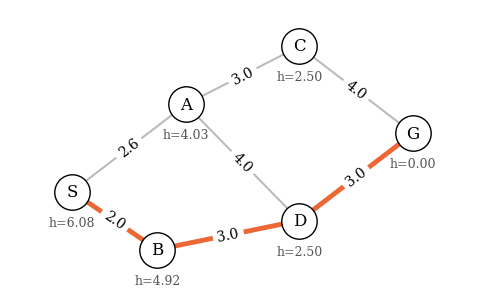

In [29]:
fig, ax = plt.subplots(figsize=(6, 3.6))
path_edges = list(zip(worked_path[:-1], worked_path[1:]))
nx.draw_networkx_edges(worked_graph, worked_positions, ax=ax, edge_color="#bbbbbb", width=1.5)
nx.draw_networkx_edges(worked_graph, worked_positions, edgelist=path_edges, ax=ax,
                       edge_color=ALGO_COLOURS["A*"], width=3.5)
nx.draw_networkx_nodes(worked_graph, worked_positions, ax=ax, node_color="white",
                       edgecolors="black", node_size=650)
nx.draw_networkx_labels(worked_graph, worked_positions, ax=ax, font_family="serif", font_size=12)
edge_labels = nx.get_edge_attributes(worked_graph, "weight")
nx.draw_networkx_edge_labels(worked_graph, worked_positions, edge_labels=edge_labels, ax=ax,
                             font_family="serif", font_size=10)
for node, (x, y) in worked_positions.items():           # heuristic value under each node
    ax.text(x, y - 0.42, f"h={worked_h(node, 'G'):.2f}", ha="center", va="top",
            fontsize=9, color=GREY_TEXT)
ax.set_axis_off()
ax.margins(0.12)
save_fig(fig, "worked_graph")
plt.show()

**What this shows:** The orange route S → B → D → G costs 2 + 3 + 3 = 8. Both routes through A cost 9.6 (2.6 + 3 + 4 via C, or 2.6 + 4 + 3 via D). The grey numbers are the straight-line distances to G, and each is at most the true remaining cost; for example h(B) = 4.92 while the real cost from B is 6.

---
# 5. Test environments

We test on two kinds of map:

1. **Grids** built with `make_grid` from Section 2.2, in three sizes (10×10, 50×50, 100×100):
   * *random walls*: each cell is a wall with probability 0.25, used both 4-connected and 8-connected
     (the **same** wall layout for both, so they can be compared fairly);
   * *maze*: randomised depth-first search maze with 10% extra openings, 4-connected.
2. **The Cork city road network** from OpenStreetMap, downloaded with OSMnx (Boeing, 2017).

The heuristic used on each map is the one that is admissible **and** as large as possible there:
Manhattan on 4-connected grids, octile on 8-connected grids, haversine (straight-line distance on the
Earth's surface) on the road network.

## 5.1 Grid environments

**What this cell does:** Builds the nine grid environments and stores each one with its heuristic in a
dictionary called `ENVIRONMENTS`.

**Why we need it:** Sections 6 and 7 loop over this dictionary, so every algorithm is run on exactly the same maps.

**What to look for in the output:** Nine names, three per size.

In [30]:
WALL_RATIO = 0.25
GRID_SIZES = [10, 50, 100]
ENVIRONMENTS = {}       # name -> dict(graph, heuristic, weight attribute)

for n in GRID_SIZES:
    walls = rng.random((n, n)) < WALL_RATIO          # one wall layout, used for 4- and 8-connected
    ENVIRONMENTS[f"Random {n}x{n}, 4-conn"] = {
        "graph": grid_graph_from_blocked(walls, 4), "h": manhattan, "weight": "weight"}
    ENVIRONMENTS[f"Random {n}x{n}, 8-conn"] = {
        "graph": grid_graph_from_blocked(walls, 8), "h": octile, "weight": "weight"}
    ENVIRONMENTS[f"Maze {n}x{n}, 4-conn"] = {
        "graph": make_grid(n, 4, kind="maze"), "h": manhattan, "weight": "weight"}

for name in ENVIRONMENTS:
    print(name)

Random 10x10, 4-conn
Random 10x10, 8-conn
Maze 10x10, 4-conn
Random 50x50, 4-conn
Random 50x50, 8-conn
Maze 50x50, 4-conn
Random 100x100, 4-conn
Random 100x100, 8-conn
Maze 100x100, 4-conn


## 5.2 The Cork road network

OSMnx returns a `MultiDiGraph`: a directed graph that may have **several parallel edges** between the same two
junctions (for example a main road and a slip road). In a `MultiDiGraph`, `G[u][v]` is not the edge's data but a
dictionary keyed by an edge number (`{0: {...}, 1: {...}}`). Our code reads `G[u][v]["length"]` directly, so it
would break.

We therefore convert it to a simple `nx.DiGraph` with **one** edge per direction. When there are parallel edges we
keep the **shortest** one (and its travel time), because a shortest-path search would always prefer it anyway.
We keep the node attributes `x` (longitude) and `y` (latitude) for the haversine heuristic and for drawing.

**What this cell does:** If `data/cork_drive.graphml` does not exist and OSMnx is installed, downloads the Cork
driving network, adds speeds and travel times, keeps the largest strongly connected component (so every
junction can reach every other one), and saves the file. Otherwise it does nothing.

**Why we need it:** Downloading takes time and needs the internet. Saving the file makes later runs fast and
guarantees they use exactly the same map.

**What to look for in the output:** Either "Downloaded and saved" (first run) or "Using saved file".

In [31]:
CORK_FILE = DATA_DIR / "cork_drive.graphml"

if not CORK_FILE.exists():
    if not HAVE_OSMNX:
        raise RuntimeError("data/cork_drive.graphml is missing and osmnx is not installed.")
    cork_multi = ox.graph_from_place("Cork, Ireland", network_type="drive")
    cork_multi = ox.add_edge_speeds(cork_multi)          # speed_kph on every edge (km/h)
    cork_multi = ox.add_edge_travel_times(cork_multi)    # travel_time on every edge (seconds)
    cork_multi = ox.truncate.largest_component(cork_multi, strongly=True)
    ox.save_graphml(cork_multi, CORK_FILE)
    print("Downloaded and saved", CORK_FILE)
else:
    print("Using saved file", CORK_FILE)

Using saved file data\cork_drive.graphml


**What this cell does:** Defines `to_simple_digraph`, which converts the `MultiDiGraph` into a simple `DiGraph`,
keeping the shortest of any parallel edges, as explained above.

**Why we need it:** Without it, `G[u][v]["length"]` fails on the road network.

**What to look for in the output:** Nothing is printed.

In [32]:
def to_simple_digraph(multi):
    simple = nx.DiGraph()
    for node, data in multi.nodes(data=True):
        simple.add_node(node, x=float(data["x"]), y=float(data["y"]))   # longitude, latitude
    for u, v, data in multi.edges(data=True):
        length = float(data["length"])                 # metres
        if simple.has_edge(u, v) and simple[u][v]["length"] <= length:
            continue                                   # a shorter parallel edge is already stored
        simple.add_edge(u, v, length=length,
                        travel_time=float(data["travel_time"]),   # seconds
                        speed_kph=float(data["speed_kph"]))       # km/h
    return simple

**What this cell does:** Loads the saved file with NetworkX, converts it, and counts the parallel edges that were
merged.

**Why we need it:** This is the road graph used in every Cork experiment.

**What to look for in the output:** Several thousand junctions (nodes) and road segments (edges), plus the number
of parallel edges that were dropped.

In [33]:
cork_multi = nx.read_graphml(CORK_FILE, node_type=int, force_multigraph=True)
cork = to_simple_digraph(cork_multi)
print("MultiDiGraph:", cork_multi.number_of_nodes(), "nodes,", cork_multi.number_of_edges(), "edges")
print("Simple DiGraph:", cork.number_of_nodes(), "nodes,", cork.number_of_edges(), "edges")
print("Parallel edges dropped:", cork_multi.number_of_edges() - cork.number_of_edges())

MultiDiGraph: 10161 nodes, 22272 edges
Simple DiGraph: 10161 nodes, 21878 edges
Parallel edges dropped: 394


**What this cell does:** Finds the top speed on any road in the graph and builds the two road heuristics:
haversine distance in metres (for `length` weights) and haversine distance divided by the top speed, in seconds
(for `travel_time` weights). It also adds Cork to `ENVIRONMENTS`.

**Why we need it:** A heuristic must be in the **same units** as the edge weights. Dividing by the top speed
gives the time the trip would take if you could drive in a straight line at the fastest legal speed, which can
never be longer than the real travel time. That keeps it admissible (Section 7e).

**What to look for in the output:** The top speed in km/h.

In [34]:
CORK_MAX_SPEED_KPH = max(data["speed_kph"] for u, v, data in cork.edges(data=True))
cork_h_length = make_haversine(cork)                                  # metres
cork_h_time = make_haversine(cork, max_speed_kph=CORK_MAX_SPEED_KPH)  # seconds
print(f"Top speed on any Cork road: {CORK_MAX_SPEED_KPH:.0f} km/h")

ENVIRONMENTS["Cork roads (length)"] = {"graph": cork, "h": cork_h_length, "weight": "length"}

Top speed on any Cork road: 120 km/h


**What this cell does:** Checks that both road heuristics are **consistent**: for every road segment `(u, v)`,
`h(u) ≤ cost(u, v) + h(v)`, using one fixed goal junction. It reports the number of violations and the largest one.

**Why we need it:** Haversine distance is a straight line, so it should never be longer than a road. Checking this on
real data guards against surprises such as rounded edge lengths.

**What to look for in the output:** Zero violations (or only violations of a tiny size, far below a millimetre).

In [35]:
def consistency_violations(G, h, goal, weight):
    count, worst = 0, 0.0
    for u, v, data in G.edges(data=True):
        excess = h(u, goal) - (data[weight] + h(v, goal))   # > 0 means h is inconsistent here
        if excess > 1e-9:
            count += 1
            worst = max(worst, excess)
    return count, worst

some_goal = sorted(cork.nodes)[0]
for label, h, weight in [("haversine, length", cork_h_length, "length"),
                         ("haversine / top speed, travel_time", cork_h_time, "travel_time")]:
    count, worst = consistency_violations(cork, h, some_goal, weight)
    print(f"{label}: {count} violations out of {cork.number_of_edges()} edges (largest {worst:.2e})")

haversine, length: 0 violations out of 21878 edges (largest 0.00e+00)


haversine / top speed, travel_time: 0 violations out of 21878 edges (largest 0.00e+00)

**What this shows:** Neither road heuristic breaks the consistency condition on any of the 21,878 road segments (for this goal; the same argument holds for any goal). Haversine distance is a straight line on the Earth's surface, so it can never be longer than a road between the same two points. Dividing by the top speed (120 km/h) keeps the time heuristic below every real travel time. So A\* with these heuristics must return optimal routes in Cork, which Section 6 confirms.

## 5.3 Summary of the environments

**What this cell does:** Counts the nodes and edges of every environment and saves the table as
`tables/environments.tex`.

**Why we need it:** The experimental-setup chapter must say how big each test map is.

**What to look for in the output:** Bigger grids have more nodes. 8-connected grids have about 1.5 times as many edges
as 4-connected grids on the same walls.

In [36]:
env_rows = []
for name, env in ENVIRONMENTS.items():
    G = env["graph"]
    env_rows.append({"environment": name, "nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
                     "directed": G.is_directed(), "heuristic": env["h"].__name__,
                     "edge weight": env["weight"]})
environments_df = pd.DataFrame(env_rows)
environments_df.loc[environments_df["environment"].str.startswith("Cork"), "heuristic"] = "haversine"
save_table(environments_df, "environments")
environments_df

Saved tables\environments.tex


,environment,nodes,edges,directed,heuristic,edge weight
0,"Random 10x10, 4-conn",75,99,False,manhattan,weight
1,"Random 10x10, 8-conn",75,141,False,octile,weight
2,"Maze 10x10, 4-conn",33,32,False,manhattan,weight
3,"Random 50x50, 4-conn",1853,2719,False,manhattan,weight
4,"Random 50x50, 8-conn",1853,4249,False,octile,weight
5,"Maze 50x50, 4-conn",1207,1258,False,manhattan,weight
6,"Random 100x100, 4-conn",7495,11076,False,manhattan,weight
7,"Random 100x100, 8-conn",7495,17166,False,octile,weight
8,"Maze 100x100, 4-conn",5036,5258,False,manhattan,weight
9,Cork roads (length),10161,21878,True,haversine,length


**What this shows:** The grids range from 75 free cells (10×10) to 7,495 (100×100); about a quarter of the cells are walls. On the same walls the 8-connected grid has about 1.5 times as many edges (17,166 against 11,076 at 100×100). Mazes have few edges per node because corridors are one cell wide; the 10×10 maze is even a tree (33 nodes, 32 edges), with exactly one route between any two cells. Cork is the largest graph: 10,161 junctions and 21,878 one-way road segments.

**What this cell does:** Defines two drawing helpers that are used by several figures: `draw_grid` (walls in dark
grey) and `draw_roads` (every road segment as a thin line, using longitude and latitude).

**Why we need it:** Every map figure in the report then looks the same.

**What to look for in the output:** Nothing is printed.

In [37]:
WALL_CMAP = ListedColormap(["white", "#3a3a3a"])     # free = white, wall = dark grey

def draw_grid(ax, G):
    ax.imshow(G.graph["blocked"], cmap=WALL_CMAP, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])


def draw_roads(ax, G, colour="#c8c8c8", width=0.4):
    segments = []
    for u, v in G.edges():
        segments.append([(G.nodes[u]["x"], G.nodes[u]["y"]), (G.nodes[v]["x"], G.nodes[v]["y"])])
    ax.add_collection(LineCollection(segments, colors=colour, linewidths=width))
    ax.autoscale()
    mean_lat = np.mean([data["y"] for _, data in G.nodes(data=True)])
    ax.set_aspect(1 / math.cos(math.radians(mean_lat)))   # so the map is not stretched
    ax.set_xticks([])
    ax.set_yticks([])

**What this cell does:** Draws three example environments side by side and saves `figures/environments.pdf`.
Panel labels (a), (b), (c) are written under each panel, so the LaTeX caption can refer to them.

**Why we need it:** The reader should see what the test maps look like.

**What to look for in the output:** (a) scattered random walls, (b) a maze with corridors one cell wide,
(c) the street map of Cork.

Saved figures\environments.pdf


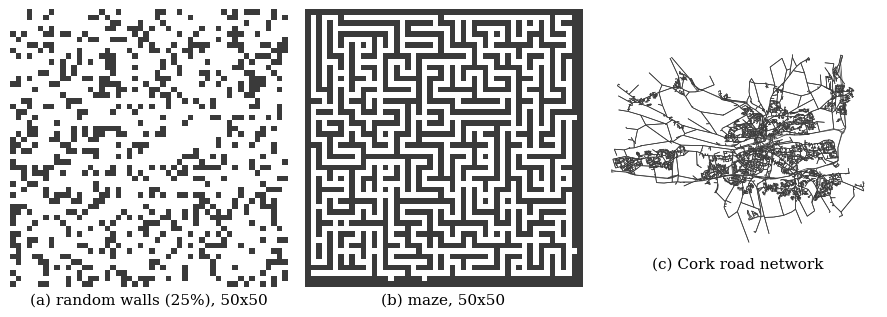

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
draw_grid(axes[0], ENVIRONMENTS["Random 50x50, 4-conn"]["graph"])
axes[0].set_xlabel("(a) random walls (25%), 50x50")
draw_grid(axes[1], ENVIRONMENTS["Maze 50x50, 4-conn"]["graph"])
axes[1].set_xlabel("(b) maze, 50x50")
draw_roads(axes[2], cork, colour="#3a3a3a", width=0.5)
axes[2].set_xlabel("(c) Cork road network")
for ax in axes:
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
save_fig(fig, "environments")
plt.show()

**What this shows:** (a) Random walls leave many open areas, so most routes need only short detours. (b) The maze has corridors one cell wide, so routes are long and winding. (c) The Cork road network is dense in the city centre and sparse in the suburbs, which are joined by a few main roads.

---
# 6. Demonstrations: four algorithms on every environment

On each of the 10 environments we draw random start–goal pairs (both ends in the largest connected piece, so a
path always exists) and run BFS, Dijkstra, greedy best-first and A\*. For every run we record:

* **cost** of the path found, and **cost ratio** = cost / optimal cost (Dijkstra's cost is the optimum), so 1.00 means optimal;
* **expanded**: nodes taken off the open list and expanded (the main measure of work);
* **peak_open**: the largest size of the open list (a measure of memory);
* **time**: run time in milliseconds, the **median of 3 runs** measured with `time.perf_counter`.

We use 50 pairs per grid and 30 pairs on Cork (each Cork search covers up to 10,000 junctions, and every search
is repeated three times for timing). This keeps the whole notebook well under five minutes.

**What this cell does:** Defines `run_algorithm`, which runs one of the four algorithms by name, and `timed_run`,
which runs it three times and returns the result with the median time.

**Why we need it:** One place decides how each algorithm is called, so all experiments are run the same way.
The median of three runs is less affected by random slow-downs of the computer than a single run.

**What to look for in the output:** Nothing is printed.

In [39]:
ALGORITHMS = ["BFS", "Dijkstra", "Greedy", "A*"]

def run_algorithm(name, G, start, goal, h, weight="weight", record_order=False):
    if name == "BFS":
        return bfs(G, start, goal, weight=weight, record_order=record_order)
    if name == "Dijkstra":
        return dijkstra(G, start, goal, weight=weight, record_order=record_order)
    if name == "Greedy":
        return greedy_best_first(G, start, goal, h, weight=weight, record_order=record_order)
    if name == "A*":
        return astar(G, start, goal, h, weight=weight, record_order=record_order)
    raise ValueError(name)


def timed_run(name, G, start, goal, h, weight="weight", repeats=3):
    run_times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        result = run_algorithm(name, G, start, goal, h, weight)
        run_times.append(time.perf_counter() - t0)
    return result, 1000 * float(np.median(run_times))     # milliseconds

**What this cell does:** Defines `run_environment`, which draws the random pairs for one environment and runs all
four algorithms on each pair. It returns one row per (pair, algorithm).

**Why we need it:** This produces the raw data for the results table.

**What to look for in the output:** Nothing is printed.

In [40]:
def run_environment(env_name, num_pairs):
    env = ENVIRONMENTS[env_name]
    G, h, weight = env["graph"], env["h"], env["weight"]
    rows = []
    for pair_id, (start, goal) in enumerate(random_pairs(G, num_pairs)):
        optimal_cost = None
        for name in ["Dijkstra", "BFS", "Greedy", "A*"]:       # Dijkstra first: it gives the optimum
            result, ms = timed_run(name, G, start, goal, h, weight)
            if name == "Dijkstra":
                optimal_cost = result.cost
            rows.append({"environment": env_name, "pair": pair_id, "algorithm": name,
                         "cost": result.cost, "cost ratio": result.cost / optimal_cost,
                         "expanded": result.expanded, "peak_open": result.peak_open, "time (ms)": ms})
    return rows

**What this cell does:** Runs every algorithm on every environment and keeps all the raw results in one table,
`demo_df`.

**Why we need it:** These are the main results of the report.

**What to look for in the output:** The number of runs and the time taken (about half a minute).

In [41]:
t0 = time.perf_counter()
demo_rows = []
for env_name in ENVIRONMENTS:
    num_pairs = 30 if env_name.startswith("Cork") else 50
    demo_rows.extend(run_environment(env_name, num_pairs))
demo_df = pd.DataFrame(demo_rows)
print(f"{len(demo_df)} runs in {time.perf_counter() - t0:.1f} s")

1920 runs in 24.1 s


**What this cell does:** Checks the two things that must be true if the code is right: A\* (with an admissible
heuristic) always finds the optimal cost, and it should almost never expand more nodes than Dijkstra.

**Why we need it:** If either check failed it would point to a bug, and we would stop and investigate rather than
report the numbers.

**What to look for in the output:** `A* optimal on every pair: True`, and A\* expanding at most as many nodes as
Dijkstra on (nearly) all pairs.

In [42]:
astar_rows = demo_df[demo_df["algorithm"] == "A*"].reset_index(drop=True)
dijkstra_rows = demo_df[demo_df["algorithm"] == "Dijkstra"].reset_index(drop=True)

astar_optimal = bool((abs(astar_rows["cost ratio"] - 1) < 1e-9).all())
not_more_work = int((astar_rows["expanded"] <= dijkstra_rows["expanded"]).sum())
print("A* optimal on every pair:", astar_optimal)
print(f"A* expanded no more nodes than Dijkstra on {not_more_work}/{len(astar_rows)} pairs")
assert astar_optimal

A* optimal on every pair: True
A* expanded no more nodes than Dijkstra on 480/480 pairs


**What this shows:** Over all 480 start–goal pairs in the 10 environments, A\* found the optimal cost every time, as the theory promises for an admissible heuristic. It also never expanded more nodes than Dijkstra. Both checks passed, so the numbers in the next table can be trusted.

**What this cell does:** Summarises the raw results as **mean ± standard deviation** for each algorithm in each
environment, and saves `tables/results.tex`.

**Why we need it:** This is the main results table of the report.

**What to look for in the output:** Dijkstra and A\* always have cost ratio 1.00 ± 0.00. Greedy has the smallest
`expanded` but a cost ratio above 1. A\* expands far fewer nodes than Dijkstra, most of all on open maps.

In [43]:
def mean_sd(values, decimals):
    return f"{values.mean():.{decimals}f} ± {values.std():.{decimals}f}"

summary_rows = []
for (env_name, name), group in demo_df.groupby(["environment", "algorithm"], sort=False):
    summary_rows.append({"environment": env_name, "algorithm": name,
                         "cost ratio": mean_sd(group["cost ratio"], 2),
                         "expanded": mean_sd(group["expanded"], 0),
                         "peak open": mean_sd(group["peak_open"], 0),
                         "time (ms)": mean_sd(group["time (ms)"], 2)})
results_df = pd.DataFrame(summary_rows)
save_table(results_df, "results")
results_df

Saved tables\results.tex


,environment,algorithm,cost ratio,expanded,peak open,time (ms)
0,"Random 10x10, 4-conn",Dijkstra,1.00 ± 0.00,36 ± 20,9 ± 3,0.19 ± 0.12
1,"Random 10x10, 4-conn",BFS,1.00 ± 0.00,36 ± 20,9 ± 3,0.10 ± 0.14
2,"Random 10x10, 4-conn",Greedy,1.01 ± 0.06,9 ± 6,9 ± 3,0.06 ± 0.03
3,"Random 10x10, 4-conn",A*,1.00 ± 0.00,10 ± 7,9 ± 3,0.06 ± 0.04
4,"Random 10x10, 8-conn",Dijkstra,1.00 ± 0.00,38 ± 21,12 ± 4,0.22 ± 0.12
5,"Random 10x10, 8-conn",BFS,1.02 ± 0.04,39 ± 22,12 ± 4,0.08 ± 0.04
6,"Random 10x10, 8-conn",Greedy,1.04 ± 0.08,8 ± 6,11 ± 5,0.08 ± 0.05
7,"Random 10x10, 8-conn",A*,1.00 ± 0.00,12 ± 12,11 ± 5,0.10 ± 0.09
8,"Maze 10x10, 4-conn",Dijkstra,1.00 ± 0.00,16 ± 8,2 ± 1,0.07 ± 0.05
9,"Maze 10x10, 4-conn",BFS,1.00 ± 0.00,16 ± 8,2 ± 1,0.04 ± 0.02


**What this shows:** A\* always matches Dijkstra's cost (ratio 1.00) but expands far fewer nodes: on the 100×100 random grid with 4 moves, 374 against 3,144 on average, about 12%. In the 100×100 maze the saving is smaller (1,164 against 2,698), because walls often force the path away from the straight line, so the heuristic is less informative. Greedy search does the least work (for example 88 nodes on the 100×100 grid) but its paths are on average up to 22% too expensive. BFS is optimal only where every edge costs the same (4-connected grids); on Cork its routes were on average 40% longer. Run times follow the expanded counts (they vary slightly between runs); BFS is fastest per node because it has no heap.

## 6.1 Where does each algorithm search? (maze)

**What this cell does:** Defines `draw_explored`, which colours the cells a search expanded and draws the path on
top in black.

**Why we need it:** A picture of the explored area is the clearest way to show *why* A\* does less work.

**What to look for in the output:** Nothing is printed.

In [44]:
def draw_explored(ax, G, result, colour):
    picture = G.graph["blocked"].astype(int)          # 0 = free, 1 = wall
    for (row, col) in result.order:
        picture[row, col] = 2                          # 2 = expanded by the search
    ax.imshow(picture, cmap=ListedColormap(["white", "#3a3a3a", colour]), vmin=0, vmax=2,
              interpolation="nearest")
    rows = [node[0] for node in result.path]
    cols = [node[1] for node in result.path]
    ax.plot(cols, rows, color="black", linewidth=1.6)
    ax.plot(cols[0], rows[0], marker="o", color="black", markersize=6)     # start
    ax.plot(cols[-1], rows[-1], marker="*", color="black", markersize=11)  # goal
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():                   # thin frame on all four sides
        spine.set_visible(True)
        spine.set_color("#888888")

**What this cell does:** Runs Dijkstra, greedy and A\* on the 50×50 maze from the top-left room `(1, 1)` to the
bottom-right room `(47, 47)`, and draws the three explored areas side by side. Saves `figures/explored_grid.pdf`.

**Why we need it:** It shows in one picture the trade-off between work done and path quality.

**What to look for in the output:** Dijkstra spreads out in every direction. Greedy rushes towards the goal and may
follow a longer route. A\* searches a smaller area than Dijkstra but finds a path of the same cost.

Saved figures\explored_grid.pdf


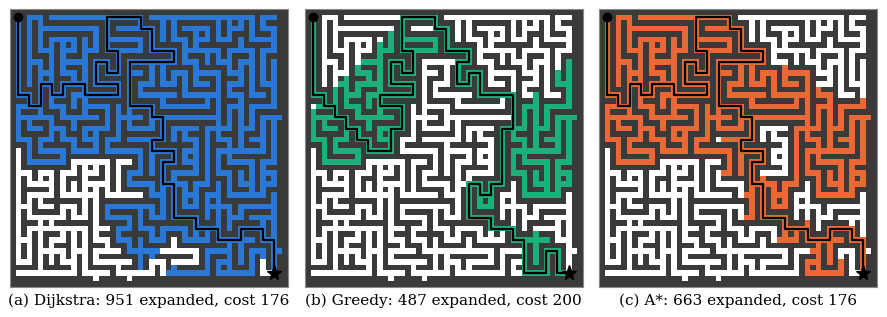

In [45]:
maze = ENVIRONMENTS["Maze 50x50, 4-conn"]["graph"]
maze_start, maze_goal = (1, 1), (47, 47)
maze_runs = {
    "Dijkstra": dijkstra(maze, maze_start, maze_goal, record_order=True),
    "Greedy": greedy_best_first(maze, maze_start, maze_goal, manhattan, record_order=True),
    "A*": astar(maze, maze_start, maze_goal, manhattan, record_order=True),
}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
panel_letters = ["a", "b", "c"]
for i, name in enumerate(maze_runs):
    result = maze_runs[name]
    draw_explored(axes[i], maze, result, ALGO_COLOURS[name])
    axes[i].set_xlabel(f"({panel_letters[i]}) {name}: {result.expanded} expanded, cost {result.cost:.0f}")
fig.tight_layout()
save_fig(fig, "explored_grid")
plt.show()

**What this shows:** Dijkstra (a) expanded 951 cells and A\* (c) 663, and both found the optimal cost of 176. A\* skipped corridors that lead away from the goal. Greedy (b) expanded the fewest cells (487) but followed a corridor that only *looked* promising: its path costs 200, 14% more than optimal. In a maze the saving from A\* is smaller than on open grids, because corridors often force the path away from the direction of the goal.

## 6.2 A long route across Cork

**What this cell does:** Picks a long route: out of 200 random junction pairs, the one whose ends are furthest
apart in a straight line. It then runs Dijkstra and A\* on road length, recording the expanded junctions.

**Why we need it:** Long routes are where a good heuristic saves the most work, and a real map is more convincing
than a grid.

**What to look for in the output:** Both algorithms report the same route length. A\* expands far fewer junctions.

In [46]:
candidate_pairs = random_pairs(cork, 200)
longest_distance = -1.0
for start, goal in candidate_pairs:
    distance = cork_h_length(start, goal)       # straight-line distance in metres
    if distance > longest_distance:
        longest_distance = distance
        cork_start, cork_goal = start, goal

cork_runs = {
    "Dijkstra": dijkstra(cork, cork_start, cork_goal, weight="length", record_order=True),
    "A*": astar(cork, cork_start, cork_goal, cork_h_length, weight="length", record_order=True),
}
print(f"Straight-line distance: {cork_h_length(cork_start, cork_goal) / 1000:.2f} km")
for name, result in cork_runs.items():
    print(f"{name:8s}: route {result.cost / 1000:.2f} km, {result.expanded} junctions expanded")

Straight-line distance: 15.25 km
Dijkstra: route 17.10 km, 9822 junctions expanded
A*      : route 17.10 km, 2999 junctions expanded


**What this shows:** The two ends are 15.25 km apart in a straight line, and the shortest route by road is 17.10 km. Dijkstra and A\* agree exactly on the route length, but Dijkstra expanded 9,822 junctions, almost the whole city (10,161), while A\* expanded 2,999, about 30%.

**What this cell does:** Draws the road network in light grey, the expanded junctions as coloured dots, and the
route in black, for Dijkstra and A\* side by side. Saves `figures/cork_route.pdf`.

**Why we need it:** It shows the "search ellipse" of A\*: it only explores junctions that could lie on a short route
towards the goal, while Dijkstra explores a circle around the start.

**What to look for in the output:** Panel (a) is coloured almost everywhere; panel (b) only in a band along the route.

Saved figures\cork_route.pdf


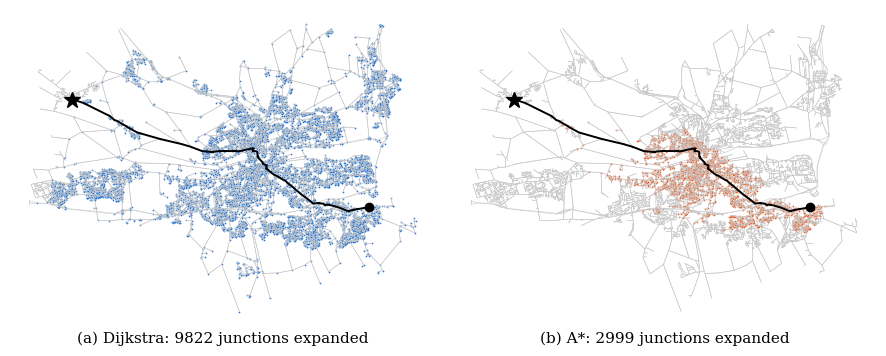

In [47]:
def draw_cork_search(ax, result, colour):
    draw_roads(ax, cork)
    xs = [cork.nodes[node]["x"] for node in result.order]
    ys = [cork.nodes[node]["y"] for node in result.order]
    ax.scatter(xs, ys, s=1.5, color=colour, linewidths=0)
    ax.plot([cork.nodes[node]["x"] for node in result.path],
            [cork.nodes[node]["y"] for node in result.path], color="black", linewidth=1.4)
    first, last = result.path[0], result.path[-1]
    ax.plot(cork.nodes[first]["x"], cork.nodes[first]["y"], marker="o", color="black", markersize=6)   # start
    ax.plot(cork.nodes[last]["x"], cork.nodes[last]["y"], marker="*", color="black", markersize=12)    # goal
    for spine in ax.spines.values():
        spine.set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
panel_letters = ["a", "b"]
for i, name in enumerate(cork_runs):
    result = cork_runs[name]
    draw_cork_search(axes[i], result, ALGO_COLOURS[name])
    axes[i].set_xlabel(f"({panel_letters[i]}) {name}: {result.expanded} junctions expanded")
fig.tight_layout()
save_fig(fig, "cork_route")
plt.show()

**What this shows:** In (a) Dijkstra's blue dots cover almost the whole city, because it searches outwards in every direction until it reaches the goal. In (b) A\*'s orange dots stay in a band around the route, mostly in the dense city centre the route passes through. Both draw exactly the same black route.

---
# 7. Parameter study

Here we change **one thing at a time** and measure the effect:

* **7a** which heuristic is used;
* **7b** the weight `w` in Weighted A\* (Pohl, 1970);
* **7c** 4- versus 8-connected moves on the same map;
* **7d** the tie-breaking rule;
* **7e** road length versus travel time on the Cork network, with a correct and a wrong heuristic.

Each part saves one table or figure for the report.

## 7a. Choice of heuristic (8-connected grid with walls)

On an 8-connected grid the true cost of a diagonal step is √2 ≈ 1.41. Manhattan distance counts it as 2, so it
**overestimates** and is not admissible here. A\* is then no longer guaranteed to find the cheapest path. The other
four heuristics never overestimate. Among those, the larger the heuristic (the closer to the true cost), the fewer
nodes A\* should expand: zero ≤ Chebyshev ≤ Euclidean ≤ octile.

**What this cell does:** On the 100×100 8-connected grid with 25% walls, runs A\* with each of the five heuristics on
the same 100 random pairs, and compares every cost with the optimal (Dijkstra) cost.

**Why we need it:** It shows the trade-off at the heart of A\*: a stronger heuristic saves work, but only an
admissible one guarantees the optimal path.

**What to look for in the output:** Octile should expand the fewest nodes of the admissible heuristics, with cost
ratio exactly 1. Manhattan should expand even fewer, but find a costlier path on some pairs.

In [48]:
grid_8 = ENVIRONMENTS["Random 100x100, 8-conn"]["graph"]
heuristic_pairs = random_pairs(grid_8, 100)
optimal_costs = []
for start, goal in heuristic_pairs:
    optimal_costs.append(dijkstra(grid_8, start, goal).cost)

heuristic_rows = []
for h in [zero, chebyshev, euclidean, octile, manhattan]:
    for pair_id, (start, goal) in enumerate(heuristic_pairs):
        result = astar(grid_8, start, goal, h)
        heuristic_rows.append({"heuristic": h.__name__, "expanded": result.expanded,
                               "cost ratio": result.cost / optimal_costs[pair_id]})
heuristic_raw = pd.DataFrame(heuristic_rows)

**What this cell does:** Summarises 7a: mean nodes expanded, mean and worst cost ratio, and how often the path was
not optimal. Saves `tables/heuristics.tex`.

**Why we need it:** This is the table for Section 7a of the report.

**What to look for in the output:** Only the Manhattan row should have a non-zero "% suboptimal".

In [49]:
ADMISSIBLE_ON_8 = {"zero": "yes", "chebyshev": "yes", "euclidean": "yes", "octile": "yes", "manhattan": "no"}
heuristic_summary = []
for name, group in heuristic_raw.groupby("heuristic", sort=False):
    suboptimal = group["cost ratio"] > 1 + 1e-9
    heuristic_summary.append({
        "heuristic": name, "admissible": ADMISSIBLE_ON_8[name],
        "mean expanded": group["expanded"].mean(),
        "mean cost ratio": group["cost ratio"].mean(),
        "worst cost ratio": group["cost ratio"].max(),
        "% suboptimal": 100 * suboptimal.mean()})
heuristics_df = pd.DataFrame(heuristic_summary)
save_table(heuristics_df, "heuristics", float_format="%.3f")
heuristics_df

Saved tables\heuristics.tex


,heuristic,admissible,mean expanded,mean cost ratio,worst cost ratio,% suboptimal
0,zero,yes,3929.60,1.000000,1.00000,0.0
1,chebyshev,yes,1118.97,1.000000,1.00000,0.0
2,euclidean,yes,834.93,1.000000,1.00000,0.0
3,octile,yes,661.97,1.000000,1.00000,0.0
4,manhattan,no,339.88,1.015497,1.07682,58.0


**What this shows:** All four admissible heuristics found the optimal path every time, and the stronger the heuristic, the less work: from 3,930 expanded nodes with h = 0 (Dijkstra) down to 662 with octile, about 6 times fewer. Manhattan expanded even fewer (340), but because it overestimates diagonal moves it returned a costlier path on 58% of the 100 pairs: 1.5% more expensive on average and 7.7% at worst. This is the trade-off: overestimating saves work but loses the guarantee of optimality.

## 7b. Weighted A\*

Weighted A\* uses `f = g + w·h` with `w ≥ 1` (Pohl, 1970). A larger `w` trusts the heuristic more, so the search
heads for the goal more eagerly and expands fewer nodes. The price is that the path may be longer, but by a
**bounded** amount: if `h` is admissible, the cost found is at most `w` times the optimal cost.

**What this cell does:** On the 100×100 8-connected grid (octile heuristic), runs Weighted A\* with
`w = 1, 1.25, 1.5, 2, 3, 5` on 50 random pairs. It checks that every cost ratio is at most `w`.

**Why we need it:** It tests the bound in practice and shows how quickly the work drops as `w` grows.

**What to look for in the output:** "Bound respected on every run: True". Expanded nodes should fall as `w` rises.

In [50]:
W_VALUES = [1, 1.25, 1.5, 2, 3, 5]
weighted_pairs = random_pairs(grid_8, 50)
weighted_rows = []
for start, goal in weighted_pairs:
    optimal = dijkstra(grid_8, start, goal).cost
    for w in W_VALUES:
        result = weighted_astar(grid_8, start, goal, octile, w=w)
        weighted_rows.append({"w": w, "expanded": result.expanded, "cost ratio": result.cost / optimal})
weighted_raw = pd.DataFrame(weighted_rows)

bound_ok = bool((weighted_raw["cost ratio"] <= weighted_raw["w"] + 1e-9).all())
print("Bound respected on every run:", bound_ok)
assert bound_ok
weighted_df = weighted_raw.groupby("w").agg(mean_expanded=("expanded", "mean"),
                                            mean_cost_ratio=("cost ratio", "mean"),
                                            worst_cost_ratio=("cost ratio", "max")).reset_index()
weighted_df.columns = ["w", "mean expanded", "mean cost ratio", "worst cost ratio"]   # readable names
save_table(weighted_df, "weighted_astar", float_format="%.3f")
weighted_df

Bound respected on every run: True
Saved tables\weighted_astar.tex


,w,mean expanded,mean cost ratio,worst cost ratio
0,1.00,530.54,1.000000,1.000000
1,1.25,151.36,1.017052,1.116514
2,1.50,107.62,1.035088,1.147273
3,2.00,86.84,1.067335,1.345006
4,3.00,79.56,1.084345,1.364933
5,5.00,76.48,1.096347,1.408205


**What this shows:** Every run respected the bound cost ≤ w × optimal. Going from w = 1 to w = 1.25 already cuts the work from 531 to 151 expanded nodes, while paths are only 1.7% more expensive on average. Beyond w = 2 there is little extra saving (87 → 76 nodes), but the cost keeps rising slowly. The worst case at w = 5 was 41% above optimal, far less than the 400% the bound allows.

**What this cell does:** Plots mean nodes expanded (left axis, blue) and mean cost ratio (right axis, orange)
against `w`, with the guaranteed bound `cost ratio = w` as a dashed grey line. Saves `figures/weighted_astar.pdf`.

**Why we need it:** One picture shows both sides of the trade-off and how far the real cost is below the bound.

**What to look for in the output:** The blue line falls steeply; the orange line stays close to 1, far below the
dashed bound.

Saved figures\weighted_astar.pdf


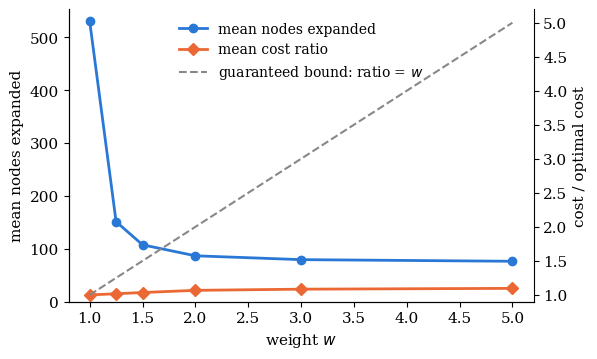

In [51]:
fig, ax_left = plt.subplots(figsize=(6, 3.8))
ax_left.plot(weighted_df["w"], weighted_df["mean expanded"], color="#2a78d6", marker="o",
             linewidth=2, label="mean nodes expanded")
ax_left.set_xlabel("weight $w$")
ax_left.set_ylabel("mean nodes expanded")
ax_left.set_ylim(bottom=0)

ax_right = ax_left.twinx()                       # second y-axis sharing the same x-axis
ax_right.spines["right"].set_visible(True)       # this axis needs its right-hand line
ax_right.plot(weighted_df["w"], weighted_df["mean cost ratio"], color="#eb6834", marker="D",
              linewidth=2, label="mean cost ratio")
ax_right.plot(W_VALUES, W_VALUES, color="#888888", linestyle="--", linewidth=1.5,
              label="guaranteed bound: ratio = $w$")
ax_right.set_ylabel("cost / optimal cost")
ax_right.set_ylim(0.9, max(W_VALUES) + 0.2)

handles = ax_left.get_legend_handles_labels()[0] + ax_right.get_legend_handles_labels()[0]
ax_left.legend(handles=handles, loc="upper center", frameon=False)
save_fig(fig, "weighted_astar")
plt.show()

**What this shows:** The blue curve shows the work dropping steeply between w = 1 and w = 1.5 and then flattening out. The orange curve (the actual mean cost ratio) stays below 1.1 for every w, far under the dashed line of the guarantee. So in practice the bound is very pessimistic, and a small weight such as 1.25–1.5 gives most of the speed-up for a small loss in quality.

## 7c. 4-connected versus 8-connected moves

**What this cell does:** Uses the two 100×100 random-wall grids from Section 5, which have exactly the **same
walls**: one allows 4 moves, the other 8. On the same 50 pairs it runs Dijkstra and A\* on both, and records the
path cost, the number of steps and the nodes expanded. Saves `tables/connectivity.tex`.

**Why we need it:** The choice of moves is part of the model, not just the algorithm. It changes both the answer
(the path) and the work needed to find it.

**What to look for in the output:** 8-connected paths are cheaper and have fewer steps. Compare the A\* savings
("A\* / Dijkstra expanded") between the two grids.

In [52]:
grid_4 = ENVIRONMENTS["Random 100x100, 4-conn"]["graph"]
connectivity_pairs = random_pairs(grid_4, 50)      # a 4-connected path is also an 8-connected path
connectivity_rows = []
for label, G, h in [("4-connected", grid_4, manhattan), ("8-connected", grid_8, octile)]:
    for start, goal in connectivity_pairs:
        d_result = dijkstra(G, start, goal)
        a_result = astar(G, start, goal, h)
        connectivity_rows.append({"moves": label, "heuristic": h.__name__, "cost": a_result.cost,
                                  "steps": len(a_result.path) - 1,
                                  "Dijkstra expanded": d_result.expanded,
                                  "A* expanded": a_result.expanded})
connectivity_df = pd.DataFrame(connectivity_rows).groupby(["moves", "heuristic"]).mean().reset_index()
connectivity_df["A* / Dijkstra expanded"] = connectivity_df["A* expanded"] / connectivity_df["Dijkstra expanded"]
save_table(connectivity_df, "connectivity")
connectivity_df

Saved tables\connectivity.tex


,moves,heuristic,cost,steps,Dijkstra expanded,A* expanded,A* / Dijkstra expanded
0,4-connected,manhattan,71.560000,71.56,3711.14,356.36,0.096024
1,8-connected,octile,63.554137,57.78,3734.40,619.88,0.165992


**What this shows:** On the same walls, diagonal moves give cheaper paths (mean cost 63.6 instead of 71.6) with fewer steps (57.8 against 71.6). Dijkstra does about the same work on both grids, but A\* saves more with 4 moves: it expands 10% of Dijkstra's nodes with Manhattan, against 17% with octile. With 4 moves Manhattan is exact on open ground, and with high_g tie-breaking A\* then heads almost straight for the goal.

## 7d. Tie-breaking

On an **empty** grid many nodes have exactly the same `f` value, because the heuristic is exact. Then the
tie-breaking rule decides almost everything. Preferring the larger `g` (the node closest to the goal along its
path) is the rule recommended by Amit Patel (Red Blob Games).

**What this cell does:** On empty 50×50 grids (4-connected with Manhattan, 8-connected with octile), runs A\* with the
three tie-breaking rules on the same 50 random pairs, and saves the mean nodes expanded as `tables/tie_breaking.tex`.

**Why we need it:** It shows that an implementation detail that does not change the cost can change the work by a
large factor.

**What to look for in the output:** The cost is identical for all three rules; `high_g` expands far fewer nodes.

In [53]:
tie_rows = []
for label, connectivity, h in [("4-connected", 4, manhattan), ("8-connected", 8, octile)]:
    empty_grid = make_grid(50, connectivity, kind="empty")
    tie_pairs = random_pairs(empty_grid, 50)
    for rule in ["high_g", "low_g", "fifo"]:
        expanded_counts, costs = [], []
        for start, goal in tie_pairs:
            result = astar(empty_grid, start, goal, h, tie_break=rule)
            expanded_counts.append(result.expanded)
            costs.append(result.cost)
        tie_rows.append({"grid": label, "tie-break": rule, "mean cost": np.mean(costs),
                         "mean expanded": np.mean(expanded_counts)})
tie_df = pd.DataFrame(tie_rows)
save_table(tie_df, "tie_breaking")
tie_df

Saved tables\tie_breaking.tex


,grid,tie-break,mean cost,mean expanded
0,4-connected,high_g,33.920000,33.92
1,4-connected,low_g,33.920000,300.06
2,4-connected,fifo,33.920000,300.06
3,8-connected,high_g,27.779049,51.30
4,8-connected,low_g,27.779049,105.28
5,8-connected,fifo,27.779049,96.72


**What this shows:** All three rules give exactly the same path costs, as they must: tie-breaking only chooses between equally good options. But the work differs a lot. On the empty 4-connected grid high_g expands on average 33.9 nodes, exactly the number of steps in the path, while low_g and fifo expand 300, about 9 times more. On the 8-connected grid high_g still roughly halves the work (51 against about 100).

**What this cell does:** Draws the cells expanded by each rule for one diagonal search, `(5, 5)` to
`(44, 44)` on the empty 4-connected grid. Saves `figures/tie_breaking.pdf`.

**Why we need it:** The picture makes the table easy to explain in the presentation.

**What to look for in the output:** `high_g` colours only a thin line of cells; the other rules colour much more of
the square, even though every path has the same cost (78).

Saved figures\tie_breaking.pdf


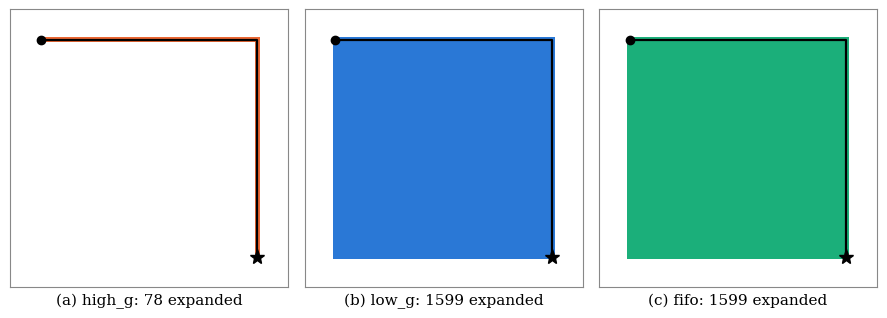

In [54]:
empty_4 = make_grid(50, 4, kind="empty")
tie_colours = {"high_g": "#eb6834", "low_g": "#2a78d6", "fifo": "#1baf7a"}
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
panel_letters = ["a", "b", "c"]
for i, rule in enumerate(["high_g", "low_g", "fifo"]):
    result = astar(empty_4, (5, 5), (44, 44), manhattan, tie_break=rule, record_order=True)
    draw_explored(axes[i], empty_4, result, tie_colours[rule])
    axes[i].set_xlabel(f"({panel_letters[i]}) {rule}: {result.expanded} expanded")
fig.tight_layout()
save_fig(fig, "tie_breaking")
plt.show()

**What this shows:** With high_g (a), A\* walks straight to the goal and expands only the 78 cells on one path. With low_g (b) and fifo (c) it expands 1,599 cells: every cell of the 40×40 square between start and goal except the goal itself, because every one of those cells has the same f = 78, and these rules do not prefer the cells closer to the goal.

## 7e. Cork: road length versus travel time

On the road network we can minimise **distance** (edge weight `length`, in metres) or **time** (edge weight
`travel_time`, in seconds). The heuristic must estimate the same quantity as the weights:

* For length, the haversine distance in metres is admissible: no road is shorter than the straight line.
* For time, we divide the haversine distance by the **top speed on any road in the graph**
  (`CORK_MAX_SPEED_KPH`). No real trip can be faster than driving the straight line at that top speed, so this
  never overestimates.
* A **wrong** heuristic: the plain haversine distance in metres used against travel times in seconds. Metres are
  much bigger numbers than seconds, so `h` hugely overestimates and A\* behaves almost like greedy search.

**What this cell does:** On 30 random Cork pairs, runs Dijkstra and A\* for both weights, plus the wrong
heuristic for travel time. Each cost is divided by the Dijkstra cost for the same weight.

**Why we need it:** It shows that admissibility is about **units and meaning**, not just the formula.

**What to look for in the output:** Ratio exactly 1 for the two correct A\* versions; ratio above 1 for the wrong
heuristic, which also expands very few nodes.

In [55]:
road_pairs = random_pairs(cork, 30)
road_settings = [   # (label, weight attribute, heuristic or None for Dijkstra)
    ("length: Dijkstra", "length", None),
    ("length: A*, haversine (m)", "length", cork_h_length),
    ("time: Dijkstra", "travel_time", None),
    ("time: A*, haversine / top speed (s)", "travel_time", cork_h_time),
    ("time: A*, haversine in metres (wrong)", "travel_time", cork_h_length),
]
road_rows = []
for pair_id, (start, goal) in enumerate(road_pairs):
    optimal = {"length": dijkstra(cork, start, goal, weight="length").cost,
               "travel_time": dijkstra(cork, start, goal, weight="travel_time").cost}
    for label, weight, h in road_settings:
        result = best_first_search(cork, start, goal, h=h, weight=weight)
        road_rows.append({"setting": label, "expanded": result.expanded,
                          "cost ratio": result.cost / optimal[weight]})
road_raw = pd.DataFrame(road_rows)

**What this cell does:** Summarises 7e and saves `tables/cork_weights.tex`.

**Why we need it:** This is the table for Section 7e of the report.

**What to look for in the output:** Only the "wrong" row should have a non-zero "% suboptimal".

In [56]:
road_summary = []
for label, group in road_raw.groupby("setting", sort=False):
    road_summary.append({"setting": label, "mean expanded": group["expanded"].mean(),
                         "mean cost ratio": group["cost ratio"].mean(),
                         "worst cost ratio": group["cost ratio"].max(),
                         "% suboptimal": 100 * (group["cost ratio"] > 1 + 1e-9).mean()})
cork_weights_df = pd.DataFrame(road_summary)
save_table(cork_weights_df, "cork_weights", float_format="%.3f")
cork_weights_df

Saved tables\cork_weights.tex


,setting,mean expanded,mean cost ratio,worst cost ratio,% suboptimal
0,length: Dijkstra,4659.300000,1.000000,1.000000,0.000000
1,"length: A*, haversine (m)",1215.366667,1.000000,1.000000,0.000000
2,time: Dijkstra,4731.333333,1.000000,1.000000,0.000000
3,"time: A*, haversine / top speed (s)",2998.100000,1.000000,1.000000,0.000000
4,"time: A*, haversine in metres (wrong)",154.800000,1.294122,2.097653,93.333333


**What this shows:** Both correct A\* versions found the optimal route every time. With length weights, haversine cuts the work from 4,659 to 1,215 junctions (26%). With travel-time weights the admissible heuristic (haversine / 120 km/h) is much weaker and saves less (2,998 against 4,731), because most city roads are far slower than 120 km/h, so the heuristic underestimates a lot. The wrong heuristic (metres treated as seconds) expands only 155 junctions, but returns a slower route on 93% of pairs: 29% slower on average and 110% at worst.

**What this cell does:** For the long route from Section 6.2, finds the **shortest** route (length) and the
**fastest** route (travel time), and the route returned with the wrong heuristic. It compares their length and
time, and draws all three on the map. Saves `figures/cork_length_vs_time.pdf`.

**Why we need it:** It shows that "shortest" and "fastest" are different questions with different answers, and what
a wrong heuristic does to a real route.

**What to look for in the output:** The fastest route is longer in km but quicker in minutes. The wrong-heuristic
route is slower than the fastest route.

shortest (length)              : 17.10 km, 20.06 min, 2999 junctions expanded
fastest (travel time)          : 21.21 km, 16.58 min, 8782 junctions expanded
wrong heuristic (travel time)  : 26.36 km, 22.73 min, 122 junctions expanded


Saved figures\cork_length_vs_time.pdf


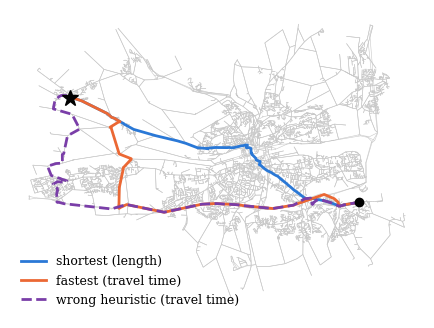

In [57]:
shortest = astar(cork, cork_start, cork_goal, cork_h_length, weight="length")
fastest = astar(cork, cork_start, cork_goal, cork_h_time, weight="travel_time")
wrong = astar(cork, cork_start, cork_goal, cork_h_length, weight="travel_time")
route_styles = [("shortest (length)", shortest, "#2a78d6", "-"),
                ("fastest (travel time)", fastest, "#eb6834", "-"),
                ("wrong heuristic (travel time)", wrong, "#7a3ea8", "--")]
for label, result, colour, style in route_styles:
    km = path_cost(cork, result.path, "length") / 1000
    minutes = path_cost(cork, result.path, "travel_time") / 60
    print(f"{label:31s}: {km:5.2f} km, {minutes:5.2f} min, {result.expanded} junctions expanded")

fig, ax = plt.subplots(figsize=(6, 4))
draw_roads(ax, cork)
for label, result, colour, style in route_styles:
    ax.plot([cork.nodes[node]["x"] for node in result.path], [cork.nodes[node]["y"] for node in result.path],
            color=colour, linestyle=style, linewidth=2, label=label)
ax.plot(cork.nodes[cork_start]["x"], cork.nodes[cork_start]["y"], marker="o", color="black", markersize=6)
ax.plot(cork.nodes[cork_goal]["x"], cork.nodes[cork_goal]["y"], marker="*", color="black", markersize=12)
ax.legend(loc="lower left", frameon=False, fontsize=9)
for spine in ax.spines.values():
    spine.set_visible(False)
save_fig(fig, "cork_length_vs_time")
plt.show()

**What this shows:** The shortest route is 17.10 km but takes 20.1 minutes; the fastest route is about 4 km longer (21.21 km) but 3.5 minutes quicker (16.6 minutes), because it uses faster main roads. The route found with the wrong heuristic is the worst on both counts: 26.36 km and 22.7 minutes. It expanded only 122 junctions, because it rushed towards the goal like greedy search.

---
# 8. Limitations

## 8.1 Memory grows with the size of the map

A\* keeps every node it has generated: the open list (the heap) plus the `best_g` and `parent` dictionaries. In the
worst case this is every node in the graph, so memory, not time, is often what limits A\* on large maps
(Russell & Norvig, 2020, Ch. 3).

**What this cell does:** For grids of size `n = 20, 40, 60, 80, 100` (8-connected, 25% walls), runs Dijkstra and A\*
on 20 random pairs per size and records the peak size of the open list and the total number of entries pushed
onto it (`generated`).

**Why we need it:** It measures how memory grows with map size, which is the main practical limitation of A\*.

**What to look for in the output:** Both measures grow with `n` for both algorithms. A\* stays below Dijkstra in
`generated`, but its peak open list is not always smaller.

In [58]:
MEMORY_SIZES = [20, 40, 60, 80, 100]
memory_rows = []
memory_grids = {}                       # keep the grids for the next experiment
for n in MEMORY_SIZES:
    G = make_grid(n, 8, WALL_RATIO, kind="random")
    memory_grids[n] = G
    for start, goal in random_pairs(G, 20):
        for name in ["Dijkstra", "A*"]:
            result = run_algorithm(name, G, start, goal, octile)
            memory_rows.append({"n": n, "algorithm": name, "peak_open": result.peak_open,
                                "generated": result.generated})
memory_df = pd.DataFrame(memory_rows).groupby(["n", "algorithm"]).mean().reset_index()
memory_df

,n,algorithm,peak_open,generated
0,20,A*,26.00,72.90
1,20,Dijkstra,24.15,174.05
2,40,A*,61.10,226.15
3,40,Dijkstra,49.80,713.20
4,60,A*,78.65,317.35
5,60,Dijkstra,67.75,1117.20
6,80,A*,127.60,633.90
7,80,Dijkstra,98.70,2428.45
8,100,A*,140.30,827.85
9,100,Dijkstra,121.30,3355.25


**What this shows:** For both algorithms the total number of entries generated grows quickly with n: for Dijkstra from 174 at n = 20 to 3,355 at n = 100, roughly in proportion to the number of cells (n²). A\* generates about 4 times fewer (828 at n = 100). The peak size of the open list grows much more slowly, roughly in proportion to n. Surprisingly, A\*'s peak is slightly *larger* than Dijkstra's (140 against 121 at n = 100); the cells below explain why.

**What this cell does:** Plots the two memory measures against grid size, in two panels, and saves
`figures/memory_growth.pdf`.

**Why we need it:** A picture of the growth is easier to read than the table.

**What to look for in the output:** Panel (b) grows roughly with the number of cells (`n²`); panel (a), the frontier,
grows much more slowly, roughly with `n`.

Saved figures\memory_growth.pdf


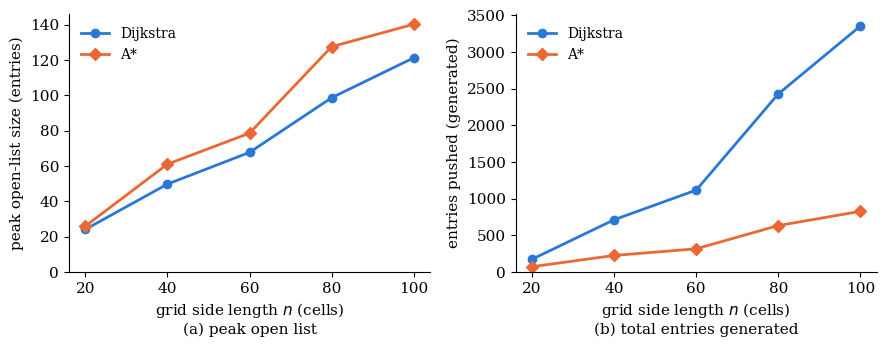

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for name in ["Dijkstra", "A*"]:
    rows = memory_df[memory_df["algorithm"] == name]
    axes[0].plot(rows["n"], rows["peak_open"], color=ALGO_COLOURS[name], marker=ALGO_MARKERS[name],
                 linewidth=2, label=name)
    axes[1].plot(rows["n"], rows["generated"], color=ALGO_COLOURS[name], marker=ALGO_MARKERS[name],
                 linewidth=2, label=name)
axes[0].set_ylabel("peak open-list size (entries)")
axes[1].set_ylabel("entries pushed (generated)")
axes[0].set_xlabel("grid side length $n$ (cells)\n(a) peak open list")
axes[1].set_xlabel("grid side length $n$ (cells)\n(b) total entries generated")
for ax in axes:
    ax.set_xticks(MEMORY_SIZES)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "memory_growth")
plt.show()

**What this shows:** Panel (b) shows A\*'s main advantage: the number of entries it generates grows much more slowly than Dijkstra's. Panel (a) shows a limitation: the open list itself is not smaller with A\*, and both curves keep growing with the map. On a very large map (a whole country, say) storing every generated node becomes the bottleneck.

**Why is A\*'s open list sometimes *larger* than Dijkstra's?** Panel (a) shows that A\* saves a lot of *work*
(panel b) but not open-list memory. The reason is rule 2 of `best_first_search`: when a cheaper route to a node is
found, we push a **new** heap entry and leave the old one behind as a stale entry, to be skipped later. Dijkstra
expands nodes in order of `g`, so the first route it finds to a node is nearly always the cheapest, and it creates
very few stale entries. A\* expands in order of `f = g + h`, so it often reaches a node first by a route that is not the
cheapest, and later improves it, leaving a stale duplicate in the heap.

**What this cell does:** Defines `open_list_at_peak`, a copy of the A\* loop (same rules as `best_first_search`) that
counts how many entries in the heap are stale at the moment the heap is largest.

**Why we need it:** It tests the explanation above with numbers instead of guessing.

**What to look for in the output:** Nothing is printed.

In [60]:
def open_list_at_peak(G, start, goal, h):
    """Return (size, number of stale entries) of the open list at its largest."""
    best_g, counter = {start: 0.0}, 0
    open_heap = [(h(start, goal), 0.0, counter, 0.0, start)]
    peak_size, peak_stale = 1, 0
    while open_heap:
        f, tie, count, g_value, node = heapq.heappop(open_heap)
        if g_value > best_g[node]:
            continue
        if node == goal:
            break
        for neighbour, edge_data in G[node].items():
            g_new = g_value + edge_data["weight"]
            if g_new < best_g.get(neighbour, math.inf):
                best_g[neighbour] = g_new
                counter += 1
                heapq.heappush(open_heap, (g_new + h(neighbour, goal), -g_new, counter, g_new, neighbour))
        if len(open_heap) > peak_size:                  # new peak: count the stale entries in it
            peak_size, peak_stale = len(open_heap), 0
            for entry in open_heap:
                if entry[3] > best_g[entry[4]]:          # entry[3] = stored g, entry[4] = node
                    peak_stale += 1
    return peak_size, peak_stale

**What this cell does:** On the 100×100 grid from the memory experiment, measures the open list at its peak for
Dijkstra (`h = zero`) and A\* (`h = octile`) on 40 random pairs, split into stale and live entries. Saves
`tables/open_list_peak.tex`.

**Why we need it:** It explains the surprising result in panel (a).

**What to look for in the output:** A\* should have fewer **live** entries than Dijkstra but many more **stale** ones.

In [61]:
peak_rows = []
peak_pairs = random_pairs(memory_grids[100], 40)
for name, h in [("Dijkstra", zero), ("A*", octile)]:
    sizes, stales = [], []
    for start, goal in peak_pairs:
        size, stale = open_list_at_peak(memory_grids[100], start, goal, h)
        sizes.append(size)
        stales.append(stale)
    peak_rows.append({"algorithm": name, "open list at peak": np.mean(sizes),
                      "stale entries": np.mean(stales), "live entries": np.mean(sizes) - np.mean(stales)})
open_peak_df = pd.DataFrame(peak_rows)
save_table(open_peak_df, "open_list_peak", float_format="%.1f")
open_peak_df

Saved tables\open_list_peak.tex


,algorithm,open list at peak,stale entries,live entries
0,Dijkstra,119.525,1.65,117.875
1,A*,187.725,76.35,111.375


**What this shows:** At its peak A\*'s open list held 188 entries against Dijkstra's 120, but 76 of A\*'s were stale, against fewer than 2 for Dijkstra. The live entries, the real frontier, are about the same (111 against 118). So the extra memory is the price of leaving outdated entries in the heap instead of updating them. It does not affect correctness, because stale entries are skipped when popped (rule 2).

## 8.2 A better heuristic for roads: ALT landmarks (optional extension)

The haversine heuristic ignores the road layout, and for travel time it is weak because it assumes you can drive
everywhere at the top speed. The **ALT** method (A\*, Landmarks, Triangle inequality; Goldberg & Harrelson, 2005)
builds a much stronger heuristic by **pre-computing** exact distances from and to a few "landmark" junctions.

For a landmark `L`, the triangle inequality gives two lower bounds on the true distance `d(u, t)`:

* `d(L, t) − d(L, u)` (going from `L` to `t` cannot be shorter than going `L → u → t`),
* `d(u, L) − d(t, L)`.

The heuristic is the largest of these bounds over all landmarks (and 0). It never overestimates, so A\* stays
optimal. The price is pre-processing time and memory: two distance tables per landmark.

**What this cell does:** Defines `all_distances`, a Dijkstra that computes the distance from one source to **every**
node (no goal). With `reverse=True` it follows edges backwards, giving the distance from every node **to** the source.

**Why we need it:** ALT needs complete distance tables for each landmark. This is our own code, not NetworkX's.

**What to look for in the output:** Nothing is printed.

In [62]:
def all_distances(G, source, weight, reverse=False):
    if reverse:
        neighbours_of = G.pred      # incoming edges: distances TO the source
    else:
        neighbours_of = G.succ      # outgoing edges: distances FROM the source
    distance = {source: 0.0}
    heap = [(0.0, source)]
    while heap:
        d, node = heapq.heappop(heap)
        if d > distance[node]:
            continue                            # stale entry
        for neighbour, edge_data in neighbours_of[node].items():
            new_d = d + edge_data[weight]
            if new_d < distance.get(neighbour, math.inf):
                distance[neighbour] = new_d
                heapq.heappush(heap, (new_d, neighbour))
    return distance

**What this cell does:** Chooses landmarks by **farthest-point selection**: start from a random junction, take the
junction farthest from it as the first landmark, then repeatedly add the junction farthest from all landmarks
chosen so far. Landmarks then sit around the edge of the map, where they give the best bounds.

**Why we need it:** Goldberg & Harrelson (2005) show that landmarks spread around the edge of the map work well.

**What to look for in the output:** Nothing is printed.

In [63]:
def choose_landmarks(G, num_landmarks, weight):
    nodes = sorted(G.nodes)
    random_node = nodes[rng.integers(len(nodes))]
    from_random = all_distances(G, random_node, weight)
    landmarks = [max(from_random, key=from_random.get)]          # farthest junction
    closest_landmark = all_distances(G, landmarks[0], weight)    # distance to nearest landmark
    while len(landmarks) < num_landmarks:
        new_landmark = max(closest_landmark, key=closest_landmark.get)
        landmarks.append(new_landmark)
        from_new = all_distances(G, new_landmark, weight)
        for node in closest_landmark:
            closest_landmark[node] = min(closest_landmark[node], from_new[node])
    return landmarks

**What this cell does:** Defines `make_alt`, which pre-computes the distance tables and returns a heuristic with the
usual `h(u, goal)` signature.

**Why we need it:** With the same signature, the ALT heuristic plugs straight into `astar`, and nothing else changes.

**What to look for in the output:** Nothing is printed.

In [64]:
def make_alt(G, landmarks, weight):
    dist_from = {}     # dist_from[L][v] = d(L, v)
    dist_to = {}       # dist_to[L][v]   = d(v, L)
    for landmark in landmarks:
        dist_from[landmark] = all_distances(G, landmark, weight)
        dist_to[landmark] = all_distances(G, landmark, weight, reverse=True)
    def h(u, goal):
        best = 0.0
        for landmark in landmarks:
            bound_1 = dist_from[landmark][goal] - dist_from[landmark][u]
            bound_2 = dist_to[landmark][u] - dist_to[landmark][goal]
            best = max(best, bound_1, bound_2)
        return best
    return h

**What this cell does:** Builds an ALT heuristic with 8 landmarks for each weight (length and travel time), then
runs Dijkstra, A\* with haversine, and A\* with ALT on the 30 Cork pairs from Section 7e. It checks that ALT gives the
optimal cost and saves `tables/alt.tex`.

**Why we need it:** It shows how much a better heuristic can save on a real network, and what it costs to prepare.

**What to look for in the output:** Cost ratio exactly 1 for ALT, and far fewer nodes expanded than with haversine,
especially for travel time.

In [65]:
NUM_LANDMARKS = 8
alt_rows = []
for weight, haversine_h in [("length", cork_h_length), ("travel_time", cork_h_time)]:
    t0 = time.perf_counter()
    alt_h = make_alt(cork, choose_landmarks(cork, NUM_LANDMARKS, weight), weight)
    preprocessing_s = time.perf_counter() - t0
    for label, h in [("Dijkstra", None), ("A*, haversine", haversine_h), ("A*, ALT (8 landmarks)", alt_h)]:
        expanded, ratios = [], []
        for start, goal in road_pairs:
            optimal = dijkstra(cork, start, goal, weight=weight).cost
            result = best_first_search(cork, start, goal, h=h, weight=weight)
            expanded.append(result.expanded)
            ratios.append(result.cost / optimal)
        assert max(ratios) < 1 + 1e-9                      # every version must stay optimal
        setup_time = 0.0
        if h is alt_h:
            setup_time = preprocessing_s                   # only ALT needs pre-processing
        alt_rows.append({"weight": weight, "method": label, "mean expanded": np.mean(expanded),
                         "mean cost ratio": np.mean(ratios), "preprocessing (s)": setup_time})
alt_df = pd.DataFrame(alt_rows)
save_table(alt_df, "alt")
alt_df

Saved tables\alt.tex


,weight,method,mean expanded,mean cost ratio,preprocessing (s)
0,length,Dijkstra,4659.300000,1.0,0.000000
1,length,"A*, haversine",1215.366667,1.0,0.000000
2,length,"A*, ALT (8 landmarks)",392.600000,1.0,1.262702
3,travel_time,Dijkstra,4731.333333,1.0,0.000000
4,travel_time,"A*, haversine",2998.100000,1.0,0.000000
5,travel_time,"A*, ALT (8 landmarks)",591.900000,1.0,1.171688


**What this shows:** ALT keeps every route optimal and cuts the work a lot. For length it expands 393 junctions, against 1,215 with haversine and 4,659 with Dijkstra. For travel time the gain is even bigger: 592 against 2,998 with haversine / top speed, because the landmark distances already include the real road speeds. The price is about 1.3 seconds of pre-processing per weight, plus 16 distance tables of 10,161 entries each (8 landmarks × 2 directions).

---
# 9. Animation for the slides

**What this cell does:** Makes a GIF of Dijkstra and A\* filling in the same 50×50 maze as Section 6.1, side by side.
Both searches expand nodes at the **same speed** (the same number of nodes per frame), so A\* finishes first.
When a search finishes, its path appears in black. Saved as `figures/dijkstra_vs_astar.gif`.

**Why we need it:** For the presentation only. Animation shows the difference between the algorithms in seconds.
(It is not used in the written report, which uses `figures/explored_grid.pdf` instead.)

**What to look for in the output:** The orange A\* region stops growing and shows its path while the blue Dijkstra
region is still spreading.

In [66]:
gif_runs = {"Dijkstra": maze_runs["Dijkstra"], "A*": maze_runs["A*"]}
NUM_FRAMES = 60
HOLD_FRAMES = 12                                    # extra frames showing the final picture
nodes_per_frame = math.ceil(len(gif_runs["Dijkstra"].order) / NUM_FRAMES)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.4))
images, path_lines = {}, {}
for i, name in enumerate(gif_runs):
    colour_map = ListedColormap(["white", "#3a3a3a", ALGO_COLOURS[name]])
    images[name] = axes[i].imshow(maze.graph["blocked"].astype(int), cmap=colour_map, vmin=0, vmax=2)
    path_lines[name] = axes[i].plot([], [], color="black", linewidth=1.8)[0]   # empty line, filled in later
    axes[i].set_xticks([])
    axes[i].set_yticks([])
    axes[i].set_xlabel(name)
fig.tight_layout()
plt.close(fig)        # do not show the empty first frame here; the next cell shows the GIF

**What this cell does:** Defines the function that draws frame number `frame`, then builds the animation and saves it
with `PillowWriter`.

**Why we need it:** `matplotlib.animation` calls this function once per frame.

**What to look for in the output:** The file path of the saved GIF, then the animation itself.

Saved figures\dijkstra_vs_astar.gif


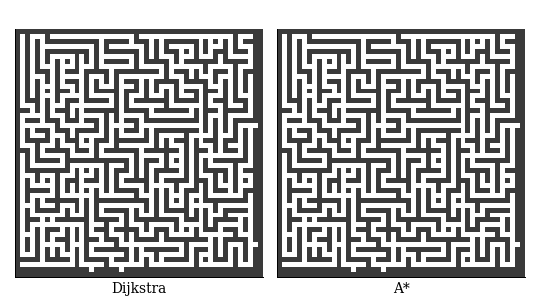

In [67]:
def draw_frame(frame):
    for name, result in gif_runs.items():
        count = frame * nodes_per_frame                 # how many expansions to show so far
        picture = maze.graph["blocked"].astype(int)
        for (row, col) in result.order[:count]:
            picture[row, col] = 2
        images[name].set_data(picture)
        if count >= len(result.order):                  # this search has finished: show its path
            path_lines[name].set_data([node[1] for node in result.path], [node[0] for node in result.path])
    return list(images.values()) + list(path_lines.values())

gif_animation = animation.FuncAnimation(fig, draw_frame, frames=NUM_FRAMES + HOLD_FRAMES + 1, blit=True)
gif_path = FIG_DIR / "dijkstra_vs_astar.gif"
gif_animation.save(gif_path, writer=animation.PillowWriter(fps=12), dpi=90)
plt.close(fig)
print(f"Saved {gif_path}")
display(Image(filename=str(gif_path)))

**What this shows:** Both searches advance at the same rate. A\* reaches the goal after 663 expansions and draws its path, while Dijkstra keeps spreading until 951. Use it on the slide that introduces the heuristic.

---
# 10. Summary of saved files

**What this cell does:** Lists every file in `figures/` and `tables/`, with the notebook section that made it and the
report chapter it belongs to. It also checks that no expected file is missing.

**Why we need it:** A checklist for writing the report on Overleaf: upload these two folders and `\input` or
`\includegraphics` each file in the chapter shown.

**What to look for in the output:** "All expected files are present", and one row per file.

In [68]:
FILE_MAP = {   # file -> (notebook section, report chapter)
    "tables/versions.tex": ("1", "Appendix: software versions"),
    "tables/correctness.tex": ("3", "Method: validation"),
    "tables/worked_example.tex": ("4", "Background: worked example"),
    "figures/worked_graph.pdf": ("4", "Background: worked example"),
    "tables/environments.tex": ("5", "Experimental setup"),
    "figures/environments.pdf": ("5", "Experimental setup"),
    "tables/results.tex": ("6", "Results"),
    "figures/explored_grid.pdf": ("6", "Results"),
    "figures/cork_route.pdf": ("6", "Results"),
    "tables/heuristics.tex": ("7a", "Results: parameter study"),
    "tables/weighted_astar.tex": ("7b", "Results: parameter study"),
    "figures/weighted_astar.pdf": ("7b", "Results: parameter study"),
    "tables/connectivity.tex": ("7c", "Results: parameter study"),
    "tables/tie_breaking.tex": ("7d", "Results: parameter study"),
    "figures/tie_breaking.pdf": ("7d", "Results: parameter study"),
    "tables/cork_weights.tex": ("7e", "Results: parameter study"),
    "figures/cork_length_vs_time.pdf": ("7e", "Results: parameter study"),
    "figures/memory_growth.pdf": ("8", "Discussion: limitations"),
    "tables/open_list_peak.tex": ("8", "Discussion: limitations"),
    "tables/alt.tex": ("8", "Discussion: extensions (ALT)"),
    "figures/dijkstra_vs_astar.gif": ("9", "Slides only"),
}
missing = [name for name in FILE_MAP if not Path(name).exists()]
if missing:
    print("MISSING:", missing)
else:
    print("All expected files are present")

All expected files are present


**What this cell does:** Lists the files actually present in `figures/` and `tables/`, with their sizes.

**Why we need it:** It shows at a glance what to upload to Overleaf, and flags any old file not made by this notebook.

**What to look for in the output:** One row per file; every row should have a section number.

In [69]:
saved_rows = []
for folder in [FIG_DIR, TABLE_DIR]:
    for path in sorted(folder.iterdir()):
        key = path.as_posix()
        section, chapter = FILE_MAP.get(key, ("-", "not made by this notebook"))
        saved_rows.append({"file": key, "section": section, "report chapter": chapter,
                           "size (kB)": round(path.stat().st_size / 1024, 1)})
pd.DataFrame(saved_rows)

,file,section,report chapter,size (kB)
0,figures/cork_length_vs_time.pdf,7e,Results: parameter study,266.2
1,figures/cork_route.pdf,6,Results,712.0
2,figures/dijkstra_vs_astar.gif,9,Slides only,88.7
3,figures/environments.pdf,5,Experimental setup,263.0
4,figures/explored_grid.pdf,6,Results,17.9
5,figures/memory_growth.pdf,8,Discussion: limitations,16.8
6,figures/tie_breaking.pdf,7d,Results: parameter study,13.3
7,figures/weighted_astar.pdf,7b,Results: parameter study,15.4
8,figures/worked_graph.pdf,4,Background: worked example,10.1
9,tables/alt.tex,8,Discussion: extensions (ALT),0.5


**What this shows:** The notebook produced every figure and table the report needs. The PDFs and `.tex` files can be
uploaded to Overleaf as they are; the GIF is for the slides only.